## 0. Setup

**Imports and environment check.** All libraries used anywhere in the notebook are imported here once.
The cell then
1. sets `ROOT`, the project folder (the folder that holds this notebook; Jupyter starts there), so all paths
   start there;
2. chooses the device: the GPU if PyTorch can see one, otherwise the CPU;
3. prints the PyTorch and torchvision versions, whether a GPU is visible (must be `True`) and its name.

`%matplotlib inline` makes plots appear in the notebook; `ShowImage` and `display` show saved PNG files and tables;
the `pd.set_option` calls make wide tables readable.

In [1]:
import random, re, subprocess, time, urllib.request, zipfile
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from IPython.display import Image as ShowImage, display
from PIL import Image
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, StratifiedShuffleSplit
from torchvision import models

%matplotlib inline
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

ROOT = Path.cwd()                       # Jupyter starts in the notebook's folder = the project folder
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("project folder:", ROOT)
print(torch.__version__, torchvision.__version__, torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO GPU")

project folder: /home/kilwa/Desktop/DL project/DL-Brain-Tumor
2.14.1+rocm7.2 0.29.1+rocm7.2 True AMD Radeon RX 9070 XT


## 1. Configuration

All design choices of the proposal (classes, models, depths, protocols, seeds, epochs, learning-rate grids, ...)
are set in this one cell.

1. Paths: `data/raw/kaggle` (the Kaggle images), `data/raw/figshare` (`.mat` files with tumor masks),
   `irshad_groups.csv` (the patient/duplicate group of every image) and the output folders in `results/`
   (`tables/`, `figures/`, `checkpoints/`), which are created if they do not exist.
2. Image settings: 4 classes (`K = 4`), image size 224×224, and the ImageNet mean/std used to normalize inputs (the
   pre-trained networks expect inputs normalized exactly like their ImageNet training data).
3. Design: 2 architectures × 3 fine-tuning depths × 3 protocols, 5 folds, seeds per protocol, and 15 %
   validation data.
4. Training: batch 32 (prediction in batches of 256), at most 20 epochs, early-stopping patience 5, weight decay 0.01.
5. Learning-rate grids for the search, the number of calibration bins (15), the number of bootstrap repetitions
   (2000), and the three depth comparisons used in RQ1 and RQ2.

In [2]:
DATA = ROOT / "data"
KAGGLE_DIR = DATA / "raw" / "kaggle"           # contains Training/ and Testing/
FIGSHARE_DIR = DATA / "raw" / "figshare"       # contains the *.mat files
GROUPS_CSV = DATA / "raw" / "irshad_groups.csv"
RESULTS = ROOT / "results"
TABLES = RESULTS / "tables"
FIGS = RESULTS / "figures"
CHECKPOINTS = RESULTS / "checkpoints"          # grouped-CV model weights (needed by Grad-CAM)
for folder in (TABLES, FIGS, CHECKPOINTS):
    folder.mkdir(parents=True, exist_ok=True)

CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]  
K = len(CLASSES)
IMG = 224
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

ARCHS = ["resnet50", "efficientnet_b0"]
DEPTHS = ["frozen", "partial", "full"]
PROTOCOLS = ["official", "random", "grouped"]
N_FOLDS = 5
SEEDS = {"official": [0, 1, 2], "random": [0, 1], "grouped": [0, 1]}
VAL_FRAC = 0.15

BATCH = 32
EVAL_BATCH = 256
EPOCHS = 20
PATIENCE = 5
WEIGHT_DECAY = 0.01

LR_HEAD_GRID = [1e-4, 3e-4, 1e-3]
LR_BACKBONE_GRID = [1e-5, 3e-5, 1e-4]

ECE_BINS = 15
N_BOOT = 2000
DEPTH_PAIRS = [("full", "frozen"), ("partial", "frozen"), ("full", "partial")]

**`run_name(protocol, arch, depth, seed, fold)`** builds a readable name for one training run, e.g.
`grouped__resnet50__full__s0__f3`. It labels the progress lines and the saved model weights.

In [3]:
def run_name(protocol, arch, depth, seed, fold):
    return f"{protocol}__{arch}__{depth}__s{seed}__f{fold}"

**`all_runs()`** lists the 138 main training runs as tuples `(protocol, arch, depth, seed, fold)`.

Counting: per architecture and depth there are 3 official runs (3 seeds × 1 split) + 10 random-CV runs
(2 seeds × 5 folds) + 10 grouped-CV runs (2 seeds × 5 folds) = 23; and 2 architectures × 3 depths × 23 = **138**.

In [4]:
def all_runs():
    """The 138 main training runs: 2 archs x 3 depths x (3 + 5*2 + 5*2)."""
    runs = []
    for arch in ARCHS:
        for depth in DEPTHS:
            for protocol in PROTOCOLS:
                for seed in SEEDS[protocol]:
                    folds = [0] if protocol == "official" else range(N_FOLDS)
                    for fold in folds:
                        runs.append((protocol, arch, depth, seed, fold))
    return runs

print("runs in the main experiment:", len(all_runs()))

runs in the main experiment: 138


## 2. Data

### 2.1 Download

**download the three inputs** into `data/raw/` (every part is skipped if it is already there):

1. **Group file** (`irshad_groups.csv`): the patient ID and duplicate group of each Kaggle image, from a public
   leakage audit. The URL contains a fixed *commit hash*, so it always returns the same version of the file even if
   the repository changes later. `urllib.request.urlretrieve` downloads a URL to a file.
2. **Kaggle dataset** (7,200 JPEG images). `subprocess.run([...], check=True)` runs the official `kaggle`
   command-line tool as if typed in a terminal (`check=True` raises an error if it fails). It needs the user's own
   Kaggle API token in `~/.kaggle/kaggle.json`; alternatively, download the zip in a browser and unzip it into
   `data/raw/kaggle/`. The cell then counts the images (expected 7200).
3. **figshare dataset** (3,064 `.mat` files with image, tumor mask and patient ID; only needed for RQ3).
   It comes as a zip containing further zips; `zipfile.ZipFile(...).extractall` unpacks them. Expected 3064 files.


**Sources / further reading**
- [Irshad, *Brain-Tumor-MRI-Leakage-Benchmark* (GitHub, MIT license)](https://github.com/Asadullah-Irshad/Brain-Tumor-MRI-Leakage-Benchmark) — duplicate/patient audit; we use its `groups.csv`, pinned to commit `0508f1c`
- [Nickparvar, *Brain Tumor MRI Dataset*, Kaggle, version 2, CC BY 4.0, doi:10.34740/kaggle/dsv/2645886](https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset)
- [Kaggle API (official command-line tool)](https://github.com/Kaggle/kaggle-api)
- [Cheng et al., *Enhanced Performance of Brain Tumor Classification via Tumor Region Augmentation and Partition*, PLoS ONE 2015](https://doi.org/10.1371/journal.pone.0140381); dataset: [figshare 1512427](https://doi.org/10.6084/m9.figshare.1512427), CC BY 4.0

In [5]:
KAGGLE_DIR.mkdir(parents=True, exist_ok=True)
FIGSHARE_DIR.mkdir(parents=True, exist_ok=True)

# 1) Group file (patient IDs + duplicate groups) from Irshad's repository
GROUPS_URL = ("https://raw.githubusercontent.com/Asadullah-Irshad/Brain-Tumor-MRI-Leakage-Benchmark/"
              "0508f1c5eb9f947f429cee224917014b9ff67dc0/results/groups.csv")
if not GROUPS_CSV.exists():
    urllib.request.urlretrieve(GROUPS_URL, GROUPS_CSV)

# 2) Kaggle "Brain Tumor MRI Dataset" (M. Nickparvar), version 2
if not (KAGGLE_DIR / "Training").is_dir():
    subprocess.run(["kaggle", "datasets", "download", "-d", "masoudnickparvar/brain-tumor-mri-dataset",
                    "-p", str(KAGGLE_DIR), "--unzip"], check=True)
n_kaggle = sum(1 for p in KAGGLE_DIR.rglob("*") if p.suffix.lower() in (".jpg", ".jpeg", ".png"))
print(f"Kaggle images: {n_kaggle} (expected 7200)")

# 3) figshare brain tumor dataset (Cheng et al.), .mat files with image, mask and patient ID.
if len(list(FIGSHARE_DIR.rglob("*.mat"))) < 3064:
    urllib.request.urlretrieve("https://figshare.com/ndownloader/articles/1512427/versions/5", FIGSHARE_DIR / "all.zip")
    zipfile.ZipFile(FIGSHARE_DIR / "all.zip").extractall(FIGSHARE_DIR)
    for inner_zip in sorted(FIGSHARE_DIR.glob("brainTumorDataPublic_*.zip")):
        zipfile.ZipFile(inner_zip).extractall(FIGSHARE_DIR)
n_mat = sum(1 for p in FIGSHARE_DIR.rglob("*.mat") if p.stem.isdigit())
print(f"figshare .mat files: {n_mat} (expected 3064)")

Kaggle images: 7200 (expected 7200)
figshare .mat files: 3064 (expected 3064)


### 2.2 Preprocessing

Preprocessing is identical for every run: **crop the black margin -> convert to grayscale -> resize to 224×224**.

It is done once, and the result is kept in memory as one array, so all 180 training runs read exactly
the same pixels and no run wastes time decoding JPEG files.

**`crop_box(gray, thr=15, min_frac=0.01)`** — find the part of the image that is not black background.

1. `bright = gray > thr`: a True/False mask of pixels brighter than 15 (out of 255).
2. `bright.mean(axis=1)` is, for every row, the fraction of bright pixels; rows where more than 1 % of pixels are
   bright count as "content". The same is done for columns.
3. The box runs from the first to the last content row/column. If fewer than 8 rows or columns qualify (an
   almost black image), the whole image is kept.

Returns `(x0, y0, x1, y1)` — left, top, right, bottom — in the Pillow convention (right/bottom exclusive).
Why: the Kaggle images have black borders of different widths; cropping them makes the brain fill the 224×224
frame consistently.

In [6]:
def crop_box(gray, thr=15, min_frac=0.01):
    """Bounding box (x0, y0, x1, y1) of the non-black area of a grayscale array."""
    h, w = gray.shape
    bright = gray > thr
    rows = np.where(bright.mean(axis=1) > min_frac)[0]
    cols = np.where(bright.mean(axis=0) > min_frac)[0]
    if len(rows) < 8 or len(cols) < 8:
        return 0, 0, w, h
    return int(cols[0]), int(rows[0]), int(cols[-1]) + 1, int(rows[-1]) + 1

**`load_dataset()`** — read and preprocess all 7,200 Kaggle images and build the **index table** `index_df` (one row
per image). Returns `(index_df, images)`: row *i* of the table describes image *i* of the array
(`uint8`, shape 7200×224×224).

Step by step:
1. Loop over `Training/` then `Testing/`, and the 4 classes in fixed order, files sorted by name -> the row order is
   deterministic, and every later step refers to images by their **row position** (`idx`).
2. For each file: open it with Pillow, remember its format, color mode, size and file size in bytes (these become
   the features of the metadata control in Section 6), convert to grayscale (`"L"`), crop with `crop_box`, resize
   to 224×224 with bilinear interpolation. The crop box is stored too: the mask step in Section 7 needs it.
3. `merge(groups, on="rel", how="left")` joins the group file to the table on the relative path (a *left join*:
   keep every image, attach its group if found). The printed count of images without a group must be 0.
4. `patient_id` is kept as text (otherwise IDs like `"0012"` would turn into the number 12); `traceable` marks
   images whose figshare patient ID is known (the others have only a duplicate group).

In [7]:
def load_dataset():
    """Read and preprocess all Kaggle images and attach their patient/duplicate groups."""
    rows, images = [], []
    for split, folder in (("train", "Training"), ("test", "Testing")):
        for label, cls in enumerate(CLASSES):
            class_dir = KAGGLE_DIR / folder / cls
            files = sorted(p for p in class_dir.iterdir() if p.suffix.lower() in (".jpg", ".jpeg", ".png"))
            for path in files:
                im = Image.open(path)
                width, height = im.size
                gray = np.asarray(im.convert("L"))
                x0, y0, x1, y1 = crop_box(gray)
                small = Image.fromarray(gray[y0:y1, x0:x1]).resize((IMG, IMG), Image.BILINEAR)
                images.append(np.asarray(small, dtype=np.uint8))
                rows.append(dict(rel=f"{folder}/{cls}/{path.name}", split=split, cls=cls, label=label,
                                 width=width, height=height, mode=im.mode, format=im.format,
                                 bytes=path.stat().st_size, x0=x0, y0=y0, x1=x1, y1=y1))
    index_df = pd.DataFrame(rows)

    groups = pd.read_csv(GROUPS_CSV, dtype={"patient_id": str})[["rel", "patient_id", "group_id"]]
    index_df = index_df.merge(groups, on="rel", how="left")
    print("images without a group (must be 0):", int(index_df["group_id"].isna().sum()))
    index_df["group_id"] = index_df["group_id"].astype(int)
    index_df["patient_id"] = index_df["patient_id"].fillna("").astype(str).str.strip()
    index_df["traceable"] = index_df["patient_id"] != ""
    return index_df, np.stack(images)

**load the data and put it on the GPU**. The table shows images per split and class; the
expected totals are **7,200 images, 946 groups, 4,835 traceable images, 233 patients** (the values of the audited
snapshot).

The whole image array is then copied **onto the GPU once** as `x_all`, with the labels as
`y_all`. No data has to be copied from disk or CPU during training, which makes every epoch much faster than a
classic `DataLoader`.

In [8]:
index_df, images = load_dataset()
display(index_df.groupby(["split", "cls"]).size().unstack())
print("images:", len(index_df), "| groups:", index_df.group_id.nunique(),
      "| traceable images:", int(index_df.traceable.sum()),
      "| patients:", index_df.loc[index_df.traceable, "patient_id"].nunique())

x_all = torch.from_numpy(images).to(device)
y_all = torch.from_numpy(index_df["label"].to_numpy()).long().to(device)

images without a group (must be 0): 0


cls,glioma,meningioma,notumor,pituitary
split,,,,
test,400,400,400,400
train,1400,1400,1400,1400


images: 7200 | groups: 946 | traceable images: 4835 | patients: 233


/tmp/ipykernel_29740/3006721958.py:8: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  y_all = torch.from_numpy(index_df["label"].to_numpy()).long().to(device)


**`to_input(images_u8, train=False, rng=None)`** — turn a batch of preprocessed `uint8` images (B, H, W), already on the
GPU, into the normalized float tensor (B, 3, H, W) that the networks expect. With `train=True` it also applies
**data augmentation** (random changes that make the training set look larger):

1. Scale pixels to [0, 1] and add a channel axis → (B, 1, H, W).
2. *Horizontal flip* of each image with probability 0.5 (`torch.where` picks flipped or original per image).
3. *Random rotation* within ±10°: a 2×3 rotation matrix `theta` is built per image, `F.affine_grid` computes,
   for every output pixel, where to read in the input image, and `F.grid_sample` reads there with bilinear
   interpolation (pixels rotated in from outside become 0 = black). This is the "grid generator + sampler"
   from Spatial Transformer Networks; doing it on the GPU for the whole batch is much faster than rotating
   images one by one with Pillow.
4. *Brightness and contrast jitter* of ±10 %: contrast stretches values around the image mean, brightness
   multiplies; `clamp(0, 1)` keeps values valid.
5. Copy the single gray channel to 3 channels (`expand`, no extra memory) because the ImageNet models expect RGB,
   then normalize with the ImageNet mean/std.

`MEAN` and `STD` hold the ImageNet values with shape (1, 3, 1, 1), so they *broadcast* over a batch of shape
(B, 3, H, W). All random numbers come from `rng`, a seeded `torch.Generator`, so the augmentation of a run is reproducible.
Augmentation is applied only to training batches, after splitting, never to validation or test images.


**Sources / further reading**
- [Jaderberg et al., *Spatial Transformer Networks*, NeurIPS 2015 (arXiv:1506.02025)](https://arxiv.org/abs/1506.02025) and the [PyTorch spatial-transformer tutorial](https://docs.pytorch.org/tutorials/intermediate/spatial_transformer_tutorial) — origin of `affine_grid` + `grid_sample`

In [9]:
MEAN = torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1).to(device)
STD = torch.tensor(IMAGENET_STD).view(1, 3, 1, 1).to(device)


def to_input(images_u8, train=False, rng=None):
    """uint8 batch (B, H, W) on the GPU -> normalized float (B, 3, H, W).

    Training-only augmentation: horizontal flip, rotation within +-10 degrees,
    mild brightness and contrast jitter. Applied on the fly, after splitting.
    """
    x = images_u8.float().div(255.0).unsqueeze(1)
    if train:
        n = x.size(0)
        flip = (torch.rand(n, generator=rng) < 0.5).to(device)
        x = torch.where(flip.view(-1, 1, 1, 1), x.flip(-1), x)
        angle = ((torch.rand(n, generator=rng) * 2 - 1) * 10.0 * np.pi / 180.0).to(device)
        cos, sin, zero = torch.cos(angle), torch.sin(angle), torch.zeros_like(angle)
        theta = torch.stack([torch.stack([cos, -sin, zero], 1), torch.stack([sin, cos, zero], 1)], 1)
        grid = F.affine_grid(theta, list(x.shape), align_corners=False)
        x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
        brightness = (1 + (torch.rand(n, generator=rng) * 2 - 1) * 0.1).to(device).view(-1, 1, 1, 1)
        contrast = (1 + (torch.rand(n, generator=rng) * 2 - 1) * 0.1).to(device).view(-1, 1, 1, 1)
        mean = x.mean(dim=(1, 2, 3), keepdim=True)
        x = (((x - mean) * contrast + mean) * brightness).clamp(0, 1)
    x = x.expand(-1, 3, -1, -1)
    return (x - MEAN) / STD

### 2.3 Visual spot-check of the groups

**look at five groups.** `value_counts()` counts the images per group; five groups with at least 2 images
are drawn with a seeded random generator (`np.random.default_rng(0)`), and up to 6 images of each are shown in one
row. Images in one row should show the same patient or the same picture.

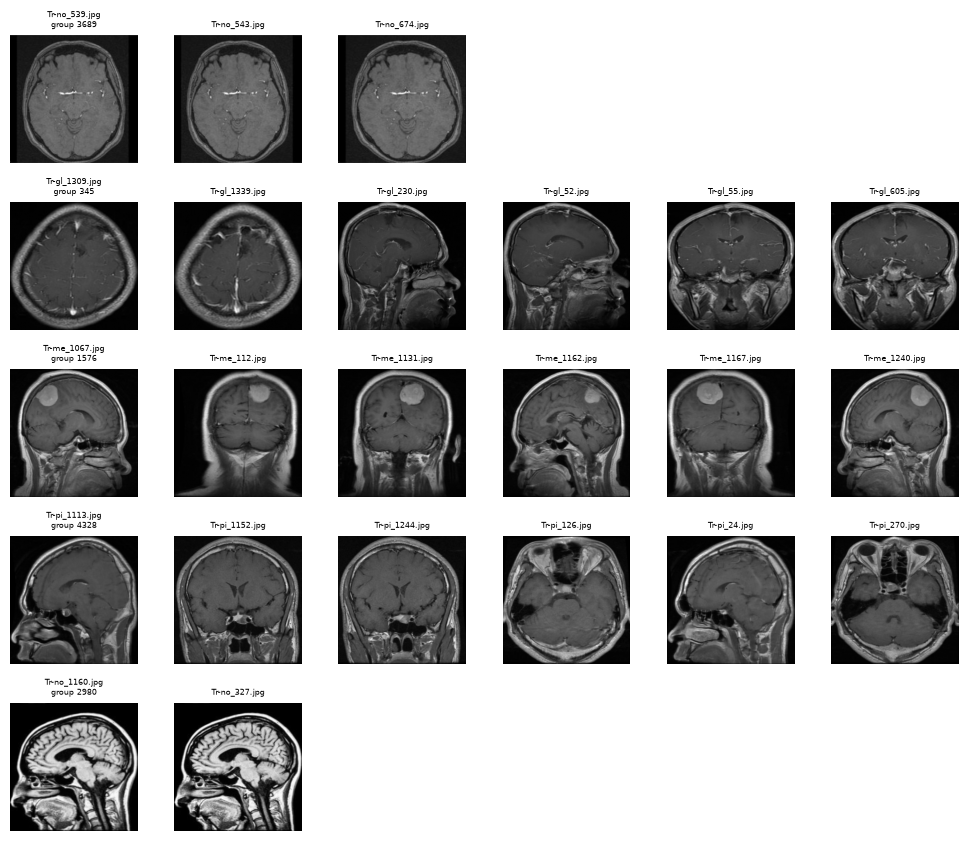

In [10]:
group_sizes = index_df.group_id.value_counts()
rng = np.random.default_rng(0)
shown_groups = rng.choice(group_sizes[group_sizes >= 2].index.to_numpy(), size=5, replace=False)
fig, axes = plt.subplots(5, 6, figsize=(10, 8.5))
for row, group in enumerate(shown_groups):
    members = index_df.index[index_df.group_id == group][:6]
    for col in range(6):
        ax = axes[row, col]; ax.axis("off")
        if col < len(members):
            ax.imshow(images[members[col]], cmap="gray")
            ax.set_title(index_df.rel[members[col]].split("/")[-1] + ("\n" + f"group {group}" if col == 0 else ""), fontsize=6)
plt.tight_layout(); plt.show()

## 3. Evaluation protocols

### The three evaluation protocols

| protocol | what is trained on | what is tested on | leaks patients? |
|---|---|---|---|
| `official` | Kaggle `Training/` (minus 15 % validation) | Kaggle `Testing/` | yes (the audit found shared patients/duplicates) |
| `random` | 4 of 5 random folds of all 7,200 images | the 5th fold | yes — the *leaky comparator* |
| `grouped` | 4 of 5 folds, built so that **no group** is split | the 5th fold | no |

A *group* is a set of images that come from the same patient or are near-duplicates of each other. If images of
one group are in both training and test data, the test measures memory of that patient rather than
generalisation to new patients — this is *data leakage*. RQ1 measures the gap Δ between random and grouped CV.

*Stratified* means every fold keeps the class proportions of the whole dataset.


**Sources / further reading**
- [Yagis et al., *Effect of data leakage in brain MRI classification using 2D CNNs*, Scientific Reports 11, 2021](https://doi.org/10.1038/s41598-021-01681-w)
- [scikit-learn user guide: cross-validation, including group-aware splitters](https://scikit-learn.org/stable/modules/cross_validation.html)
- [Irshad, *Brain-Tumor-MRI-Leakage-Benchmark* (GitHub, MIT license)](https://github.com/Asadullah-Irshad/Brain-Tumor-MRI-Leakage-Benchmark) — duplicate/patient audit; we use its `groups.csv`, pinned to commit `0508f1c`

The splits use three scikit-learn *splitter* classes (imported in the first cell). Each has a `.split(...)` method
that yields pairs of index arrays `(train_positions, test_positions)`:
- `StratifiedShuffleSplit` — one random, class-balanced hold-out split;
- `StratifiedKFold` — K class-balanced folds, ignoring groups;
- `StratifiedGroupKFold` — K folds that keep every group inside one fold while keeping class proportions as
  balanced as the group constraint allows.

**`val_split_random(pool, labels, seed)`** carves a stratified 15 % validation set out of the training positions
`pool` (ignoring groups). `next(splitter.split(...))` takes the first (and only) split. The splitter returns
positions *within* `pool`, so they are mapped back with `pool[train_pos]`, `pool[val_pos]`.

**`val_split_grouped(pool, labels, groups, seed)`** is the grouped version. `StratifiedGroupKFold` cannot ask for
"15 %" directly, so it makes `round(1/0.15) = 7` group-respecting folds and uses the first fold (≈ 14 %) as
validation. This keeps validation patients separate from training patients, so early stopping and the
learning-rate choice are not fooled by leakage either.


**Sources / further reading**
- [scikit-learn: `StratifiedShuffleSplit`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedShuffleSplit.html)
- [scikit-learn: `StratifiedKFold`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html)
- [scikit-learn: `StratifiedGroupKFold`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html)

In [11]:
def val_split_random(pool, labels, seed):
    splitter = StratifiedShuffleSplit(n_splits=1, test_size=VAL_FRAC, random_state=seed)
    train_pos, val_pos = next(splitter.split(pool, labels[pool]))
    return pool[train_pos], pool[val_pos]


def val_split_grouped(pool, labels, groups, seed):
    n_splits = int(round(1 / VAL_FRAC))          # 7 folds -> about 14% validation
    splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    train_pos, val_pos = next(splitter.split(pool, labels[pool], groups[pool]))
    return pool[train_pos], pool[val_pos]

**`get_split(index_df, protocol, seed, fold=0)`** — the single function every other step uses to get
`(train_idx, val_idx, test_idx)` (row positions into the index table).

- `official`: the Kaggle `Training/` rows are split into train/validation; `Testing/` is the test set.
- `random`: `StratifiedKFold(5, shuffle=True, random_state=seed)` — fold `fold` is the test set; validation is
  carved randomly from the rest (seed `seed*100 + fold`, so every fold gets its own but reproducible split).
- `grouped`: the same with `StratifiedGroupKFold` and the grouped validation split.

Because the splitters are seeded, calling `get_split` again (e.g. later for Grad-CAM) returns exactly the same
images.

In [12]:
def get_split(index_df, protocol, seed, fold=0):
    """Return (train_idx, val_idx, test_idx) as integer positions into the index table."""
    labels = index_df["label"].to_numpy()
    groups = index_df["group_id"].to_numpy()
    all_idx = np.arange(len(index_df))
    if protocol == "official":
        pool = all_idx[(index_df["split"] == "train").to_numpy()]
        test_idx = all_idx[(index_df["split"] == "test").to_numpy()]
        train_idx, val_idx = val_split_random(pool, labels, seed)
    elif protocol == "random":
        splitter = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
        pool, test_idx = list(splitter.split(all_idx, labels))[fold]
        train_idx, val_idx = val_split_random(pool, labels, seed * 100 + fold)
    else:  # "grouped"
        splitter = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
        pool, test_idx = list(splitter.split(all_idx, labels, groups))[fold]
        train_idx, val_idx = val_split_grouped(pool, labels, groups, seed * 100 + fold)
    return train_idx, val_idx, test_idx

**`split_summary()`** — a check over every split of every protocol and seed: sizes of train/validation/test,
the class counts of the test set, and `groups_shared_train_test` (how many groups appear in both training and test
data). It writes `split_summary.csv` and returns the table.

**check every split** and show the mean sizes per protocol. **Check:** `groups_shared_train_test` must be 0
for `grouped` and large for `random` and `official` — this is the proof that grouped CV has no patient leakage.

In [13]:
def split_summary():
    groups = index_df["group_id"].to_numpy()
    labels = index_df["label"].to_numpy()
    rows = []
    for protocol in PROTOCOLS:
        for seed in SEEDS[protocol]:
            for fold in ([0] if protocol == "official" else range(N_FOLDS)):
                train_idx, val_idx, test_idx = get_split(index_df, protocol, seed, fold)
                rows.append(dict(protocol=protocol, seed=seed, fold=fold, n_train=len(train_idx),
                                 n_val=len(val_idx), n_test=len(test_idx),
                                 test_class_counts=np.bincount(labels[test_idx], minlength=K).tolist(),
                                 groups_shared_train_test=len(set(groups[train_idx]) & set(groups[test_idx]))))
    table = pd.DataFrame(rows)
    table.to_csv(RESULTS / "split_summary.csv", index=False)
    return table


splits = split_summary()
display(splits.groupby("protocol")[["n_train", "n_val", "n_test", "groups_shared_train_test"]].mean().round(1))

,n_train,n_val,n_test,groups_shared_train_test
protocol,,,,
grouped,4936.9,823.1,1440.0,0.0
official,4760.0,840.0,1600.0,353.0
random,4896.0,864.0,1440.0,338.5


## 4. Models and fine-tuning depths

### Two networks, three fine-tuning depths

Both networks are loaded with weights pre-trained on ImageNet (1.2 M natural photos, 1000 classes) and receive a
new 4-class output layer ("head"). *Transfer learning* reuses these pre-trained features; the research question is
**how much of the network to re-train** ("fine-tuning depth"):

| depth | trainable parts |
|---|---|
| `frozen` | only the new head (the network is a fixed feature extractor) |
| `partial` | head + the last stage (ResNet-50 `layer4`; EfficientNet-B0 `features[7]` and `features[8]`) |
| `full` | every layer |

Early layers learn generic features (edges, textures) and later layers more task-specific ones, which is why the
"partial" level unfreezes the last stage.


**Sources / further reading**
- [He et al., *Deep Residual Learning for Image Recognition*, CVPR 2016 (arXiv:1512.03385)](https://arxiv.org/abs/1512.03385)
- [Tan & Le, *EfficientNet: Rethinking Model Scaling for CNNs*, ICML 2019 (arXiv:1905.11946)](https://arxiv.org/abs/1905.11946)
- [Deng et al., *ImageNet: A large-scale hierarchical image database*, CVPR 2009](https://ieeexplore.ieee.org/document/5206848)
- [torchvision documentation: models and pre-trained weights](https://docs.pytorch.org/vision/main/models.html)
- [Yosinski et al., *How transferable are features in deep neural networks?*, NeurIPS 2014 (arXiv:1411.1792)](https://arxiv.org/abs/1411.1792)

**`build_model(arch, depth)`** — create one network ready for training.

1. Load ResNet-50 or EfficientNet-B0 with the `IMAGENET1K_V1` weights (downloaded once by torchvision and cached
   in `~/.cache/torch`).
2. Replace the 1000-class output layer with `nn.Linear(in_features, 4)`. For ResNet-50 that layer is `model.fc`; for
   EfficientNet-B0 it is `model.classifier[1]` (the classifier is dropout + linear).
3. Freeze everything (`p.requires_grad = False`: the optimizer will not change these weights and no gradients are
   computed for them), then unfreeze the modules listed for the chosen depth.
4. Attach two parameter lists to the model, `head_params` and `backbone_params` (trainable non-head parameters),
   so the optimizer can give them different learning rates (Section 5), and store `arch` and `depth` on the model
   (used by `cam_layer`).

In [14]:
def build_model(arch, depth):
    if arch == "resnet50":
        model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
        model.fc = nn.Linear(model.fc.in_features, K)
        head, last_stage = [model.fc], [model.layer4]
    else:  # "efficientnet_b0"
        model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, K)
        head, last_stage = [model.classifier], [model.features[7], model.features[8]]

    trainable = {"frozen": head, "partial": head + last_stage, "full": [model]}[depth]
    for p in model.parameters():
        p.requires_grad = False
    for module in trainable:
        for p in module.parameters():
            p.requires_grad = True

    head_ids = {id(p) for module in head for p in module.parameters()}
    model.head_params = [p for p in model.parameters() if id(p) in head_ids]
    model.backbone_params = [p for p in model.parameters() if p.requires_grad and id(p) not in head_ids]
    model.arch, model.depth = arch, depth
    return model

**`set_train_mode(model)`** — like `model.train()`, but every sub-module whose parameters are all frozen is put back
into evaluation mode, so the Batch Normalization layers of a frozen part keep their ImageNet statistics instead
of updating them during training.

In [15]:
def set_train_mode(model):
    model.train()
    for module in model.modules():
        params = list(module.parameters())
        if params and not any(p.requires_grad for p in params):
            module.eval()

**`cam_layer(model)`** — the layer Grad-CAM looks at (Section 7): the last convolutional stage, which produces 7×7
feature maps for a 224×224 input in both networks (`layer4` for ResNet-50, `features[8]` for EfficientNet-B0).

In [16]:
def cam_layer(model):
    """Last convolutional stage: 7x7 feature maps for a 224x224 input in both models."""
    return model.layer4 if model.arch == "resnet50" else model.features[8]

**parameter report.** For every architecture and depth: total parameters, head parameters, trainable
backbone parameters and the trainable share of the backbone in %. `p.numel()` is the number of values in a weight
tensor.

In [17]:
rows = []
for arch in ARCHS:
    for depth in DEPTHS:
        model = build_model(arch, depth)
        n_head = sum(p.numel() for p in model.head_params)
        n_total = sum(p.numel() for p in model.parameters())
        n_backbone_trainable = sum(p.numel() for p in model.backbone_params)
        rows.append((arch, depth, n_total, n_head, n_backbone_trainable,
                     round(100 * n_backbone_trainable / (n_total - n_head), 1)))
display(pd.DataFrame(rows, columns=["arch", "depth", "total params", "head params",
                                    "trainable backbone params", "% of backbone trainable"]))

,arch,depth,total params,head params,trainable backbone params,% of backbone trainable
0,resnet50,frozen,23516228,8196,0,0.0
1,resnet50,partial,23516228,8196,14964736,63.7
2,resnet50,full,23516228,8196,23508032,100.0
3,efficientnet_b0,frozen,4012672,5124,0,0.0
4,efficientnet_b0,partial,4012672,5124,1129392,28.2
5,efficientnet_b0,full,4012672,5124,4007548,100.0


## 5. Training

### Training and evaluating one run

Everything except architecture, depth and split is identical across runs: same preprocessing, augmentation,
optimizer, schedule, early stopping and number of epochs.

**`seed_all(seed)`** — set the seed of every random number generator in use (Python, NumPy, PyTorch CPU and GPU),
so that weight initialisation of the new head, batch order and augmentation are reproducible.


**Sources / further reading**
- [PyTorch documentation: Reproducibility / randomness](https://pytorch.org/docs/stable/notes/randomness.html)

In [18]:
def seed_all(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

**`predict(model, idx)`** — class probabilities for the images at positions `idx`.

- `@torch.no_grad()` (a *decorator*: it wraps the whole function) turns off gradient bookkeeping, which saves
  memory and time during inference.
- `model.eval()` switches dropout off and makes Batch Normalization use its stored statistics.
- Images are processed in chunks of 256 (`EVAL_BATCH`).
- `torch.softmax(..., 1)` turns the 4 output scores (*logits*) into probabilities that sum to 1.

In [19]:
@torch.no_grad()
def predict(model, idx):
    model.eval()
    out = []
    for i in range(0, len(idx), EVAL_BATCH):
        batch_idx = torch.as_tensor(idx[i:i + EVAL_BATCH], device=device)
        out.append(model(to_input(x_all[batch_idx])).float())
    return torch.softmax(torch.cat(out), 1).cpu().numpy()

**`fit(arch, depth, train_idx, val_idx, seed, lr_head, lr_backbone)`** — the training loop. Returns the model with
its best weights and a dictionary of information.

1. **Setup.** Seed everything, build the model on the GPU.
2. **Optimizer: AdamW** with two *parameter groups*: the new head gets `lr_head`, the unfrozen backbone gets the
   (smaller) `lr_backbone` — pre-trained weights should move less than a freshly initialised layer. AdamW is Adam
   with *decoupled* weight decay (weight decay applied directly to the weights rather than added to the gradient).
3. **Schedule: cosine annealing** (`CosineAnnealingLR`, `T_max = 20` epochs) lowers the learning rate along a
   half cosine curve from its start value towards 0, one step per epoch.
4. **Each epoch:** set train mode (`set_train_mode`), shuffle the training positions with the seeded generator,
   and for each batch of 32: augment (`to_input(..., train=True)`), compute the cross-entropy loss, clear old
   gradients (`zero_grad`), back-propagate (`backward`), update the weights (`step`). Batches with fewer than 2
   images are skipped (Batch Normalization needs at least 2).
5. **Validation:** predict the validation set and compute its **balanced accuracy** (mean of the per-class
   recalls, so every class counts equally).
6. **Early stopping:** if validation balanced accuracy improved, store a copy of all weights (`state_dict`);
   otherwise count an epoch without improvement, and stop after 5 in a row (`PATIENCE`).
7. Restore the best weights and return them together with the best validation score, the number of epochs run
   and the training time.

**Precision.** All training uses ordinary 32-bit floats. Mixed precision (16-bit) was tried first because it is
about twice as fast, but on this ROCm build the training loss became non-finite (NaN) in the first EfficientNet-B0
run of the learning-rate search, so it was switched off and the search was restarted from zero before any test
result existed.


**Sources / further reading**
- [Kingma & Ba, *Adam: A Method for Stochastic Optimization*, ICLR 2015 (arXiv:1412.6980)](https://arxiv.org/abs/1412.6980)
- [Loshchilov & Hutter, *Decoupled Weight Decay Regularization* (AdamW), ICLR 2019 (arXiv:1711.05101)](https://arxiv.org/abs/1711.05101)
- [Loshchilov & Hutter, *SGDR: Stochastic Gradient Descent with Warm Restarts* (cosine schedule), ICLR 2017 (arXiv:1608.03983)](https://arxiv.org/abs/1608.03983)
- [Prechelt, *Early Stopping — But When?*, in Neural Networks: Tricks of the Trade (Springer)](https://link.springer.com/chapter/10.1007/978-3-642-35289-8_5)
- [Brodersen et al., *The Balanced Accuracy and Its Posterior Distribution*, ICPR 2010](https://doi.org/10.1109/ICPR.2010.764)

In [20]:
def fit(arch, depth, train_idx, val_idx, seed, lr_head, lr_backbone):
    """Train with early stopping on validation balanced accuracy. Returns (model, info)."""
    seed_all(seed)
    model = build_model(arch, depth).to(device)
    param_groups = [{"params": model.head_params, "lr": lr_head}]
    if model.backbone_params:
        param_groups.append({"params": model.backbone_params, "lr": lr_backbone})
    optimizer = torch.optim.AdamW(param_groups, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
    loss_fn = nn.CrossEntropyLoss()
    rng = torch.Generator().manual_seed(seed)          # batch order and augmentation
    labels = index_df["label"].to_numpy()
    train_t = torch.as_tensor(train_idx)

    best_bacc, best_state, epochs_no_improve = -1.0, None, 0
    start = time.time()
    for epoch in range(EPOCHS):
        set_train_mode(model)
        order = train_t[torch.randperm(len(train_t), generator=rng)]
        for i in range(0, len(order), BATCH):
            batch_idx = order[i:i + BATCH].to(device)
            if len(batch_idx) < 2:                     # BatchNorm needs at least 2 images
                continue
            batch = to_input(x_all[batch_idx], train=True, rng=rng)
            loss = loss_fn(model(batch), y_all[batch_idx])
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
        scheduler.step()
        val_bacc = balanced_accuracy_score(labels[val_idx], predict(model, val_idx).argmax(1))
        if val_bacc > best_bacc + 1e-6:
            best_bacc, epochs_no_improve = val_bacc, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= PATIENCE:
                break
    model.load_state_dict(best_state)
    info = dict(val_bacc=best_bacc, epochs_run=epoch + 1, train_seconds=round(time.time() - start, 1))
    return model, info

**`train_and_test(protocol, arch, depth, seed, fold, lr_head, lr_backbone)`** — one complete run of the main
experiment.

1. Get the split, train with `fit`, predict the **test** set once.
2. Return the test predictions as a table (one row per test image: the run's settings, the image position `idx`,
   the true `label`, the predicted class `pred`, and the 4 class probabilities `p0`–`p3`, rounded to 5 decimals).
   All tables and figures are later computed from these predictions.
3. For grouped CV only, save the model weights to `results/checkpoints/<run name>.pt` (Grad-CAM needs them).
4. Return a dictionary for the run log: learning rates, sizes, test accuracy and balanced accuracy.

The test set is used here only for the final prediction; nothing is tuned on it.

In [21]:
def train_and_test(protocol, arch, depth, seed, fold, lr_head, lr_backbone):
    name = run_name(protocol, arch, depth, seed, fold)
    train_idx, val_idx, test_idx = get_split(index_df, protocol, seed, fold)
    model, info = fit(arch, depth, train_idx, val_idx, seed, lr_head, lr_backbone)
    probs = predict(model, test_idx)
    y_test = index_df["label"].to_numpy()[test_idx]
    pred = probs.argmax(1)
    preds = pd.DataFrame({"protocol": protocol, "arch": arch, "depth": depth, "seed": seed, "fold": fold,
                          "idx": test_idx, "label": y_test, "pred": pred})
    for k in range(K):
        preds[f"p{k}"] = np.round(probs[:, k], 5)
    if protocol == "grouped":
        torch.save(model.state_dict(), CHECKPOINTS / f"{name}.pt")
    info.update(run=name, protocol=protocol, arch=arch, depth=depth, seed=seed, fold=fold,
                lr_head=lr_head, lr_backbone=lr_backbone, n_train=len(train_idx), n_val=len(val_idx),
                n_test=len(test_idx), test_acc=float((pred == y_test).mean()),
                test_bacc=float(balanced_accuracy_score(y_test, pred)))
    return preds, info

### 5.1 Learning-rate search (42 runs, validation data only)

**`lr_grid(depth)`** — the learning-rate combinations to try. `frozen` has no trainable backbone, so only the 3
head learning rates are tried (backbone rate 0). `partial` and `full` try all 3 × 3 = 9 combinations. Per
architecture: 3 + 9 + 9 = 21 runs; for both architectures **42 runs**.

**`lr_search()`** — choose one (head, backbone) learning-rate pair per architecture and depth, using **validation
data only**:
1. One split is used: the official training data with its 15 % validation part (seed 0). The test set is not
   touched.
2. Each grid point is trained with `fit` (the model is thrown away; only its validation score is kept), and one
   line with its validation balanced accuracy and training time is printed.
3. The best pair is the one with the highest validation balanced accuracy, rounded to 4 decimals; ties go to the
   smaller backbone and then the smaller head learning rate (sorting by a tuple of keys).
4. Returns the full grid as a table (saved as `results/tables/lr_search_grid.csv`) and the chosen pairs as a
   dictionary `{(arch, depth): (lr_head, lr_backbone)}`. The cell then saves the chosen pairs as
   `results/chosen_lrs.csv` and shows them. These are then **frozen** for the main experiment.

In [22]:
lr_search_grid = pd.read_csv(TABLES / "lr_search_grid.csv")
chosen_table = pd.read_csv(RESULTS / "chosen_lrs.csv")
chosen_lrs = {(r.arch, r.depth): (r.lr_head, r.lr_backbone) for r in chosen_table.itertuples()}
print(len(lr_search_grid), chosen_lrs)

42 {('resnet50', 'frozen'): (0.001, 0.0), ('resnet50', 'partial'): (0.0003, 0.0001), ('resnet50', 'full'): (0.0001, 0.0001), ('efficientnet_b0', 'frozen'): (0.001, 0.0), ('efficientnet_b0', 'partial'): (0.001, 0.0001), ('efficientnet_b0', 'full'): (0.0001, 0.0001)}


### 5.2 Main experiment (138 runs)

**`main_experiment(chosen_lrs)`** — run all 138 runs in a fixed order with the frozen learning rates and print one
progress line per run. At the end, all test predictions are saved in one file, `results/predictions.csv`, and the run log in
`results/tables/run_log.csv`. The cell then reads `predictions.csv` back as `preds` (the input of every analysis
below) and prints how many runs it contains (138 expected).

In [23]:
preds = pd.read_csv(RESULTS / "predictions.csv")
print(preds.groupby(["protocol", "arch", "depth", "seed", "fold"]).ngroups)

138


## 6. Controls and analysis

### Can the class be guessed without looking at the anatomy?

The Kaggle dataset was assembled from several sources, so file properties (image size, file format, color mode,
file size) may differ by class. A classifier could then reach high accuracy from these properties alone — a
*shortcut*. This control trains a random forest on **metadata only** with the same grouped 5-fold CV. Results
far above chance would mean the source of an image reveals its
class.


**Sources / further reading**
- [Geirhos et al., *Shortcut learning in deep neural networks*, Nature Machine Intelligence 2020 (arXiv:2004.07780)](https://arxiv.org/abs/2004.07780)
- [Breiman, *Random Forests*, Machine Learning 45, 2001](https://doi.org/10.1023/A:1010933404324)

**`metadata_control()`**

1. Build the feature matrix `X` (one row per image): width, height, aspect ratio, file size in KB, "is PNG",
   "is grayscale mode".
2. Two targets: the 4 classes (`y_4class`), and tumor (1) vs. no tumor (0) (`y_tumor`).
3. For each grouped-CV seed: for each of the 5 folds, train a random forest (300 trees) on 4 folds and predict
   the 5th. After the 5 folds every image has one out-of-fold prediction; compute balanced accuracy over all.
4. Save mean and per-seed values with the chance levels to `results/tables/control_metadata_only.csv`, and show
   the table.

A **random forest** is an ensemble of decision trees, each trained on a bootstrap sample of the rows and random
subsets of the features; the forest predicts by majority vote. `n_jobs=-1` uses all CPU cores.

In [24]:
def metadata_control():
    X = np.column_stack([index_df.width, index_df.height, index_df.width / index_df.height, index_df.bytes / 1024,
                         (index_df.format == "PNG").astype(int), (index_df["mode"] == "L").astype(int)])
    y_4class = index_df.label.to_numpy()
    y_tumor = (index_df.cls != "notumor").astype(int).to_numpy()
    groups = index_df.group_id.to_numpy()
    scores = {"four_class": [], "tumor_vs_notumor": []}
    for seed in SEEDS["grouped"]:
        splitter = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
        pred_4class, pred_tumor = np.zeros_like(y_4class), np.zeros_like(y_tumor)
        for train_idx, test_idx in splitter.split(X, y_4class, groups):
            forest = RandomForestClassifier(300, random_state=seed, n_jobs=-1)
            pred_4class[test_idx] = forest.fit(X[train_idx], y_4class[train_idx]).predict(X[test_idx])
            forest = RandomForestClassifier(300, random_state=seed, n_jobs=-1)
            pred_tumor[test_idx] = forest.fit(X[train_idx], y_tumor[train_idx]).predict(X[test_idx])
        scores["four_class"].append(balanced_accuracy_score(y_4class, pred_4class))
        scores["tumor_vs_notumor"].append(balanced_accuracy_score(y_tumor, pred_tumor))
    chance = {"four_class": 0.25, "tumor_vs_notumor": 0.5}
    table = pd.DataFrame([dict(target=t, bacc_mean=np.mean(v), bacc_seed0=v[0], bacc_seed1=v[1], chance=chance[t])
                          for t, v in scores.items()])
    table.to_csv(TABLES / "control_metadata_only.csv", index=False)
    return table


metadata_table = metadata_control()
display(metadata_table.round(4))

,target,bacc_mean,bacc_seed0,bacc_seed1,chance
0,four_class,0.5951,0.5993,0.5910,0.25
1,tumor_vs_notumor,0.8548,0.8659,0.8437,0.50


### The pre-specified tables and figures

This analysis was written **before** any result existed and was not changed afterwards. Everything is computed
from the saved per-image predictions (`predictions.csv`), never by re-training.

**`ece(probs, y, bins=ECE_BINS)`** (15 bins) — the **Expected Calibration Error**. A model is *calibrated* if, among predictions
made with 80 % confidence, about 80 % are correct.

1. Confidence = the highest predicted probability of each image; prediction = its class.
2. Split [0, 1] into 15 equal bins and put every prediction into the bin of its confidence (`np.digitize`).
3. For each bin: |accuracy in the bin − mean confidence in the bin|, weighted by the share of predictions in the bin.
4. Sum over bins. 0 = perfectly calibrated.


**Sources / further reading**
- [Naeini, Cooper & Hauskrecht, *Obtaining Well Calibrated Probabilities Using Bayesian Binning*, AAAI 2015](https://ojs.aaai.org/index.php/AAAI/article/view/9602) — origin of the ECE metric
- [Guo et al., *On Calibration of Modern Neural Networks*, ICML 2017 (arXiv:1706.04599)](https://arxiv.org/abs/1706.04599)

In [25]:
def ece(probs, y, bins=ECE_BINS):
    confidence, pred = probs.max(1), probs.argmax(1)
    edges = np.linspace(0, 1, bins + 1)
    bin_of = np.clip(np.digitize(confidence, edges[1:-1], right=True), 0, bins - 1)
    total = 0.0
    for b in range(bins):
        in_bin = bin_of == b
        if in_bin.any():
            total += in_bin.mean() * abs((pred[in_bin] == y[in_bin]).mean() - confidence[in_bin].mean())
    return float(total)

**`metrics(y, pred, probs)`** — all classification metrics from one confusion matrix.

The confusion matrix `cm[true, predicted]` gives, per class: true positives `tp` (diagonal), false negatives `fn`
(rest of the row) and false positives `fp` (rest of the column). From these:
- recall (sensitivity) = tp / (tp + fn), precision = tp / (tp + fp), F1 = harmonic mean of precision and recall;
- **balanced accuracy** = mean recall over the 4 classes; macro-F1 = mean F1;
- **AUC**: macro-averaged one-vs-rest area under the ROC curve from the probabilities;
- ECE from the function above; and the recall of each class (`rec_<class>`).

`np.maximum(..., 1)` avoids division by zero for a class that never occurs.


**Sources / further reading**
- [Brodersen et al., *The Balanced Accuracy and Its Posterior Distribution*, ICPR 2010](https://doi.org/10.1109/ICPR.2010.764)
- [scikit-learn: `roc_auc_score` (multi-class one-vs-rest)](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html)

In [26]:
def metrics(y, pred, probs):
    cm = confusion_matrix(y, pred, labels=range(K))
    tp = np.diag(cm).astype(float)
    fn, fp = cm.sum(1) - tp, cm.sum(0) - tp
    recall = tp / np.maximum(tp + fn, 1)
    precision = tp / np.maximum(tp + fp, 1)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    out = dict(n=int(len(y)), acc=float((pred == y).mean()), bacc=float(recall.mean()),
               macro_f1=float(f1.mean()), ece=ece(probs, y),
               auc=float(roc_auc_score(y, probs, multi_class="ovr", average="macro", labels=range(K))))
    for k, cls in enumerate(CLASSES):
        out[f"rec_{cls}"] = float(recall[k])
    return out

**`per_seed_table(preds)`** — metrics for every (protocol, architecture, depth, seed). Within a seed, the 5 CV folds
are **pooled**: every image is predicted exactly once (when it was in the test fold), and the metrics are computed
on all 7,200 predictions together.

**`summary_table(per_seed)`** — mean and standard deviation over seeds for each (protocol, architecture, depth),
plus the number of seeds. `ddof=1` gives the sample standard deviation.

In [27]:
PROB_COLS = [f"p{k}" for k in range(K)]


def per_seed_table(preds):
    rows = []
    for (protocol, arch, depth, seed), g in preds.groupby(["protocol", "arch", "depth", "seed"]):
        m = metrics(g.label.to_numpy(), g.pred.to_numpy(), g[PROB_COLS].to_numpy())
        rows.append(dict(protocol=protocol, arch=arch, depth=depth, seed=seed, n_folds=g.fold.nunique(), **m))
    return pd.DataFrame(rows)


def summary_table(per_seed):
    cols = ["acc", "bacc", "macro_f1", "auc", "ece"] + [f"rec_{c}" for c in CLASSES]
    g = per_seed.groupby(["protocol", "arch", "depth"])[cols]
    out = g.mean().add_suffix("_mean").join(g.std(ddof=1).add_suffix("_sd")).join(g.size().rename("n_seeds"))
    return out.reset_index()

**`group_counts(preds, protocol, arch, depth, seed)`** — the building block of the bootstrap: for one
configuration, two G × 4 tables (G = number of groups): `n_images` (number of test images per group and class) and
`n_correct` (number correctly classified).

`pd.factorize` turns group IDs into 0..G−1, and `np.add.at` adds 1 (or "correct") into the right cell for every
image. `np.add.at` is needed instead of `n_images[codes, labels] += 1` because with repeated indices the ordinary form
adds only once per unique index.

**`bacc_weighted(boot_weights, n_images, n_correct)`** — balanced accuracy for many bootstrap samples at once.
`boot_weights` is a (B × G) matrix: how often each group was drawn in each of the B bootstrap samples.
`boot_weights @ n_correct` and `boot_weights @ n_images` are then the numbers correct and total per class in every
sample; their ratio is the per-class recall, and `.mean(1)` the balanced accuracy. With a single row of ones this
gives the ordinary (non-bootstrapped) value.


**Sources / further reading**
- [NumPy: `ufunc.at` (e.g. `np.add.at`)](https://numpy.org/doc/stable/reference/generated/numpy.ufunc.at.html)

In [28]:
def group_counts(preds, protocol, arch, depth, seed):
    """Per group and class: number of test images and number correct, for one configuration."""
    g = preds[(preds.protocol == protocol) & (preds.arch == arch) & (preds.depth == depth) & (preds.seed == seed)]
    group_of = index_df["group_id"].to_numpy()[g.idx.to_numpy()]
    codes, unique_groups = pd.factorize(group_of, sort=True)
    n_images = np.zeros((len(unique_groups), K))
    n_correct = np.zeros((len(unique_groups), K))
    np.add.at(n_images, (codes, g.label.to_numpy()), 1)
    np.add.at(n_correct, (codes, g.label.to_numpy()), (g.pred.to_numpy() == g.label.to_numpy()).astype(float))
    return n_images, n_correct


def bacc_weighted(boot_weights, n_images, n_correct):
    """Balanced accuracy for bootstrap weights (B x G) over groups."""
    return ((boot_weights @ n_correct) / np.maximum(boot_weights @ n_images, 1e-9)).mean(1)

**`delta_table(preds)`** — **RQ1**: the inflation gap Δ = balanced accuracy (random CV) − balanced accuracy
(grouped CV) per architecture and depth, with 95 % confidence intervals from a **group (cluster) bootstrap**.

*Bootstrap* = estimate the uncertainty of a statistic by recomputing it on many datasets resampled with
replacement from the data. Because images of one group are not independent, whole **groups** are resampled
(cluster bootstrap): drawing G groups with replacement is the same as drawing multinomial counts
`rng.multinomial(G, [1/G]*G)`, which is a fast trick to get all B = 2000 resamples as one weight matrix.

Step by step, for each architecture:
1. For each seed s, pair random-CV seed s with grouped-CV seed s and get the group tables of all 3 depths × 2
   protocols.
2. Draw one set of 2000 group resamples and apply **the same resamples** to all configurations, so differences
   between depths are *paired* (both sides see the same patients).
3. Per depth: point estimates, the bootstrap distribution of Δ, and the error ratio
   (1 − bacc_grouped) / (1 − bacc_random) — how many times more errors grouped CV reveals.
4. The 95 % interval = 2.5th and 97.5th percentiles of the bootstrap values (*percentile interval*), computed per
   seed and averaged over seeds.
5. Contrasts Δ(full) − Δ(frozen), Δ(partial) − Δ(frozen), Δ(full) − Δ(partial) with their intervals;
   `excludes_zero` tells whether the interval lies entirely above or below 0 (the decision rule for H1).


**Sources / further reading**
- [Efron & Tibshirani, *An Introduction to the Bootstrap*, Chapman & Hall 1993](https://www.routledge.com/An-Introduction-to-the-Bootstrap/Efron-Tibshirani/p/book/9780412042317) — the percentile interval
- [Field & Welsh, *Bootstrapping clustered data*, J. R. Stat. Soc. B 69(3), 2007](https://doi.org/10.1111/j.1467-9868.2007.00593.x) — resampling whole clusters (here: whole image groups)

In [29]:
def delta_table(preds):
    rng = np.random.default_rng(0)
    rows, contrasts = [], []
    for arch in ARCHS:
        per_seed = []
        for seed in SEEDS["grouped"]:
            counts = {(protocol, depth): group_counts(preds, protocol, arch, depth, seed)
                      for protocol in ("random", "grouped") for depth in DEPTHS}
            n_groups = counts[("random", "frozen")][0].shape[0]
            boot_weights = rng.multinomial(n_groups, np.full(n_groups, 1 / n_groups), size=N_BOOT).astype(float)
            no_resampling = np.ones((1, n_groups))
            res = {}
            for depth in DEPTHS:
                boot_random = bacc_weighted(boot_weights, *counts[("random", depth)])
                boot_grouped = bacc_weighted(boot_weights, *counts[("grouped", depth)])
                bacc_random = bacc_weighted(no_resampling, *counts[("random", depth)])[0]
                bacc_grouped = bacc_weighted(no_resampling, *counts[("grouped", depth)])[0]
                res[depth] = dict(bacc_random=bacc_random, bacc_grouped=bacc_grouped,
                                  delta=bacc_random - bacc_grouped, boot=boot_random - boot_grouped,
                                  err_ratio=(1 - bacc_grouped) / max(1 - bacc_random, 1e-9))
            per_seed.append(res)
        for depth in DEPTHS:
            lo = np.mean([np.percentile(r[depth]["boot"], 2.5) for r in per_seed])
            hi = np.mean([np.percentile(r[depth]["boot"], 97.5) for r in per_seed])
            rows.append(dict(arch=arch, depth=depth, n_seeds=len(per_seed),
                             bacc_random=np.mean([r[depth]["bacc_random"] for r in per_seed]),
                             bacc_grouped=np.mean([r[depth]["bacc_grouped"] for r in per_seed]),
                             delta=np.mean([r[depth]["delta"] for r in per_seed]), delta_ci_lo=lo, delta_ci_hi=hi,
                             error_ratio=np.mean([r[depth]["err_ratio"] for r in per_seed])))
        for deeper, shallower in DEPTH_PAIRS:
            diff = [r[deeper]["boot"] - r[shallower]["boot"] for r in per_seed]
            lo = np.mean([np.percentile(d, 2.5) for d in diff])
            hi = np.mean([np.percentile(d, 97.5) for d in diff])
            estimate = np.mean([r[deeper]["delta"] - r[shallower]["delta"] for r in per_seed])
            contrasts.append(dict(arch=arch, contrast=f"delta({deeper}) - delta({shallower})", estimate=estimate,
                                  ci_lo=lo, ci_hi=hi, excludes_zero=bool(lo > 0 or hi < 0)))
    return pd.DataFrame(rows), pd.DataFrame(contrasts)

**`traceable_check(preds)`** — a control: accuracy separately for images whose patient is known from figshare
("traceable", grouping exact) and the others ("untraceable", grouping only by near-duplicates), under random
and grouped CV, and the gap between them. If the group file missed patients among the untraceable images, leakage
would remain there even under grouped CV, and the random-minus-grouped gap would be clearly smaller for the
untraceable subset than for the traceable one.

In [30]:
def traceable_check(preds):
    """Control: accuracy on figshare-traceable vs untraceable images (grouping exact vs approximate)."""
    traceable = index_df["traceable"].to_numpy()
    cv = preds[preds.protocol.isin(["random", "grouped"])].copy()
    cv["subset"] = np.where(traceable[cv.idx.to_numpy()], "traceable", "untraceable")
    cv["correct"] = (cv.pred == cv.label).astype(float)
    out = cv.groupby(["arch", "depth", "subset", "protocol"]).correct.mean().unstack("protocol").reset_index()
    out["gap"] = out["random"] - out["grouped"]
    return out

**`figures(delta, preds)`** — draws and saves the three pre-specified figures with matplotlib:
`fig_delta.png` (bars of Δ per depth with the bootstrap intervals as error bars), `fig_bacc_by_depth.png`
(balanced accuracy under random vs. grouped CV per depth) and `fig_confusion_grouped.png` (row-normalised confusion
matrices under grouped CV, each row = one true class, in %). They are saved in `results/figures/`; `plt.close(fig)` closes each figure after saving, so they are not shown here
(the cells of Sections 6.2 and 6.3 show the saved files).

In [31]:
def figures(delta, preds):
    xs = np.arange(len(DEPTHS))
    fig, axes = plt.subplots(1, len(ARCHS), figsize=(9, 3.6), sharey=True)
    for ax, arch in zip(axes, ARCHS):
        d = delta[delta.arch == arch].set_index("depth").reindex(DEPTHS)
        ax.bar(xs, 100 * d.delta, color="#4C72B0", width=0.6)
        ax.errorbar(xs, 100 * d.delta, yerr=[100 * (d.delta - d.delta_ci_lo), 100 * (d.delta_ci_hi - d.delta)],
                    fmt="none", ecolor="black", capsize=4)
        ax.axhline(0, color="black", lw=0.8)
        ax.set_xticks(xs, DEPTHS)
        ax.set_title(arch)
        ax.set_xlabel("fine-tuning depth")
    axes[0].set_ylabel("inflation gap Δ (percentage points)")
    fig.suptitle("Random-split minus patient-grouped balanced accuracy (95% group-bootstrap CI)", fontsize=10)
    fig.tight_layout()
    fig.savefig(FIGS / "fig_delta.png", dpi=200)
    plt.close(fig)

    fig, axes = plt.subplots(1, len(ARCHS), figsize=(9, 3.6), sharey=True)
    for ax, arch in zip(axes, ARCHS):
        d = delta[delta.arch == arch].set_index("depth").reindex(DEPTHS)
        ax.plot(xs, 100 * d.bacc_random, "o-", label="random 5-fold CV (leaky)")
        ax.plot(xs, 100 * d.bacc_grouped, "s--", label="patient-grouped 5-fold CV")
        ax.set_xticks(xs, DEPTHS)
        ax.set_title(arch)
        ax.set_xlabel("fine-tuning depth")
    axes[0].set_ylabel("balanced accuracy (%)")
    axes[0].legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(FIGS / "fig_bacc_by_depth.png", dpi=200)
    plt.close(fig)

    grouped = preds[preds.protocol == "grouped"]
    fig, axes = plt.subplots(len(ARCHS), len(DEPTHS), figsize=(11, 7))
    for i, arch in enumerate(ARCHS):
        for j, depth in enumerate(DEPTHS):
            ax = axes[i, j]
            g = grouped[(grouped.arch == arch) & (grouped.depth == depth)]
            cm = confusion_matrix(g.label, g.pred, labels=range(K), normalize="true")
            ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
            for r in range(K):
                for c in range(K):
                    ax.text(c, r, f"{100 * cm[r, c]:.1f}", ha="center", va="center", fontsize=7,
                            color="white" if cm[r, c] > 0.5 else "black")
            ax.set_xticks(range(K), CLASSES, fontsize=7, rotation=30)
            ax.set_yticks(range(K), CLASSES, fontsize=7)
            ax.set_title(f"{arch}, {depth}", fontsize=9)
    fig.suptitle("Patient-grouped CV: row-normalized confusion matrices (%), all seeds pooled", fontsize=10)
    fig.tight_layout()
    fig.savefig(FIGS / "fig_confusion_grouped.png", dpi=200)
    plt.close(fig)

**compute all pre-specified tables and figures** from the saved predictions and save the tables as CSV files
in `results/tables/`: `per_seed_metrics.csv`, `summary_metrics.csv`, `rq1_delta.csv`, `rq1_contrasts.csv` and
`control_traceable_subsets.csv`.

In [32]:
per_seed = per_seed_table(preds)
summary = summary_table(per_seed)
delta, contrasts = delta_table(preds)
traceable_table = traceable_check(preds)
per_seed.to_csv(TABLES / "per_seed_metrics.csv", index=False)
summary.to_csv(TABLES / "summary_metrics.csv", index=False)
delta.to_csv(TABLES / "rq1_delta.csv", index=False)
contrasts.to_csv(TABLES / "rq1_contrasts.csv", index=False)
traceable_table.to_csv(TABLES / "control_traceable_subsets.csv", index=False)
figures(delta, preds)

### 6.1 Classification metrics (mean over seeds)
the summary table. Columns: accuracy, balanced accuracy (mean and SD over seeds), macro-F1, AUC and ECE,
for every protocol, architecture and depth. Compare `random` with `grouped` rows: the difference is the inflation.

In [33]:
display(summary[["protocol", "arch", "depth", "n_seeds", "acc_mean", "bacc_mean", "bacc_sd",
                 "macro_f1_mean", "auc_mean", "ece_mean"]].round(4))

,protocol,arch,depth,n_seeds,acc_mean,bacc_mean,bacc_sd,macro_f1_mean,auc_mean,ece_mean
0,grouped,efficientnet_b0,frozen,2,0.8748,0.8748,0.0017,0.8739,0.9731,0.0130
1,grouped,efficientnet_b0,full,2,0.9480,0.9480,0.0030,0.9480,0.9929,0.0244
2,grouped,efficientnet_b0,partial,2,0.9032,0.9032,0.0039,0.9027,0.9814,0.0303
3,grouped,resnet50,frozen,2,0.8629,0.8629,0.0008,0.8626,0.9690,0.0130
4,grouped,resnet50,full,2,0.9482,0.9482,0.0051,0.9481,0.9912,0.0303
5,grouped,resnet50,partial,2,0.9349,0.9349,0.0010,0.9348,0.9900,0.0379
6,official,efficientnet_b0,frozen,3,0.8850,0.8850,0.0103,0.8819,0.9767,0.0201
7,official,efficientnet_b0,full,3,0.9583,0.9583,0.0030,0.9577,0.9958,0.0308
8,official,efficientnet_b0,partial,3,0.9519,0.9519,0.0023,0.9511,0.9923,0.0273
9,official,resnet50,frozen,3,0.8579,0.8579,0.0042,0.8541,0.9679,0.0240


### 6.2 RQ1: inflation gap Δ by fine-tuning depth
Δ per architecture and depth with its 95 % group-bootstrap interval, the contrasts between depths, and
the two RQ1 figures. **Decision rule:** H1 is supported for an architecture if the interval of
Δ(full) − Δ(frozen) excludes zero (`excludes_zero = True`) with Δ(full) larger.

,arch,depth,n_seeds,bacc_random,bacc_grouped,delta,delta_ci_lo,delta_ci_hi,error_ratio
0,resnet50,frozen,2,0.8892,0.8629,0.0262,0.0179,0.0350,1.2399
1,resnet50,partial,2,0.9811,0.9349,0.0463,0.0333,0.0612,3.4951
2,resnet50,full,2,0.9837,0.9482,0.0356,0.0239,0.0484,3.2079
3,efficientnet_b0,frozen,2,0.9074,0.8748,0.0326,0.0228,0.0429,1.3526
4,efficientnet_b0,partial,2,0.9763,0.9032,0.0731,0.0562,0.0922,4.0984
5,efficientnet_b0,full,2,0.9856,0.9480,0.0376,0.0260,0.0512,3.6216


,arch,contrast,estimate,ci_lo,ci_hi,excludes_zero
0,resnet50,delta(full) - delta(frozen),0.0093,-0.0035,0.0236,False
1,resnet50,delta(partial) - delta(frozen),0.0200,0.0068,0.0346,True
2,resnet50,delta(full) - delta(partial),-0.0107,-0.0200,-0.0019,True
3,efficientnet_b0,delta(full) - delta(frozen),0.0049,-0.0065,0.0186,False
4,efficientnet_b0,delta(partial) - delta(frozen),0.0405,0.0262,0.0569,True
5,efficientnet_b0,delta(full) - delta(partial),-0.0356,-0.0476,-0.0240,True


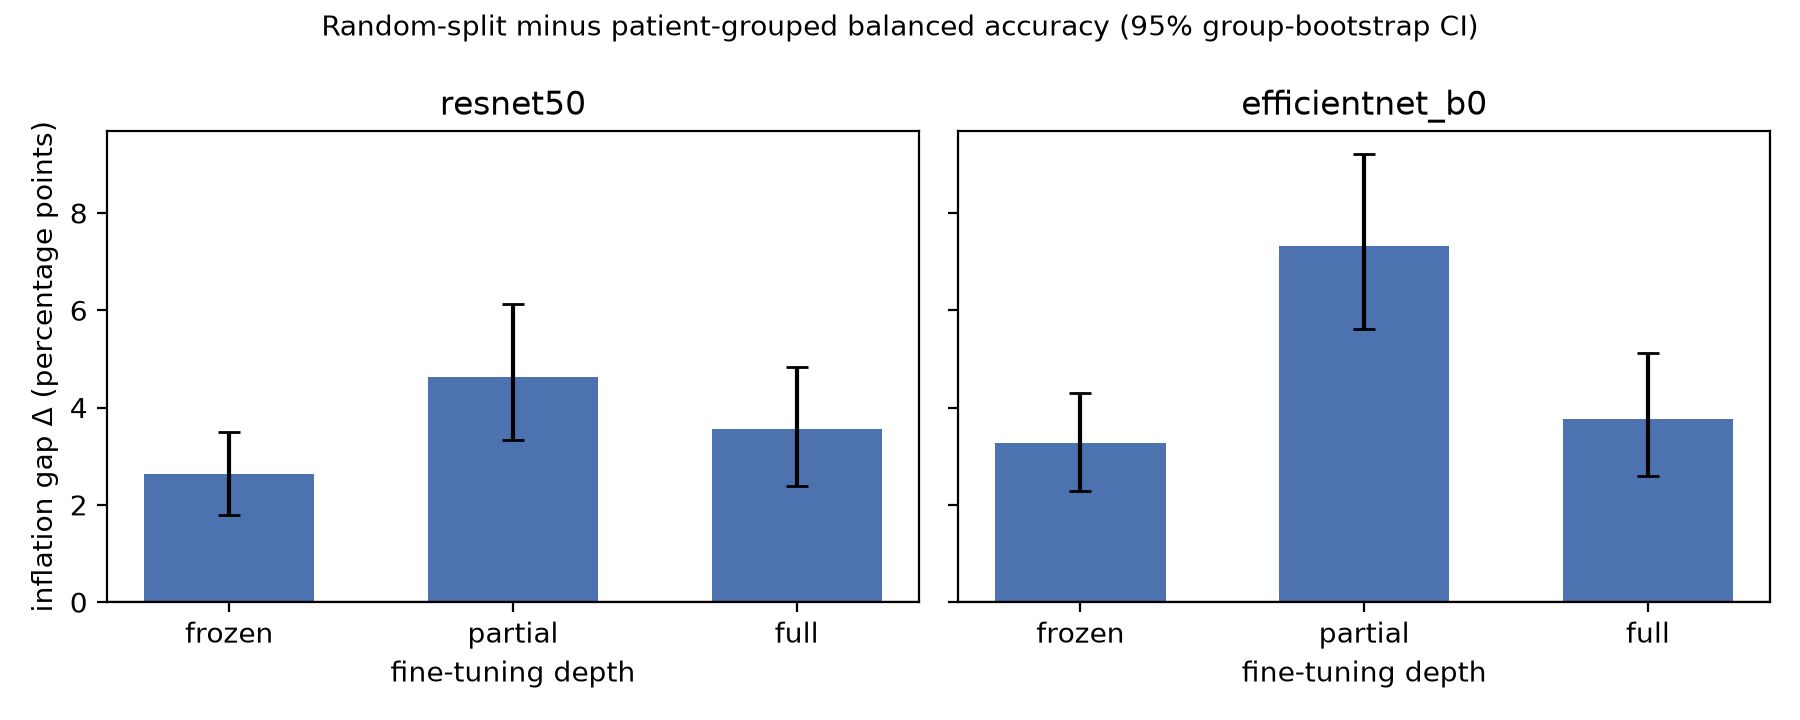

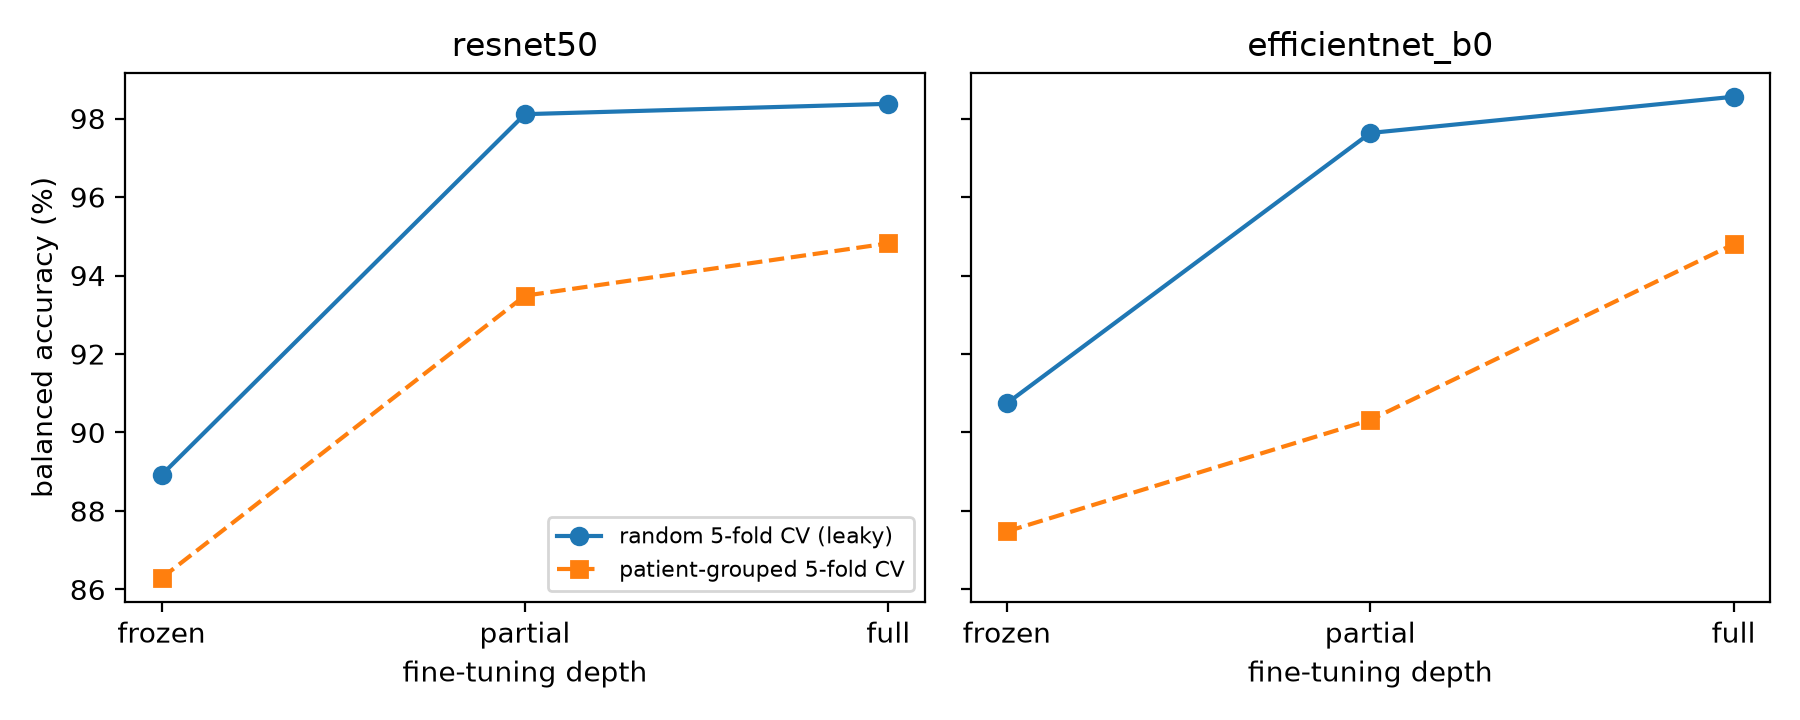

In [34]:
display(delta.round(4)); display(contrasts.round(4))
display(ShowImage(str(FIGS / "fig_delta.png"))); display(ShowImage(str(FIGS / "fig_bacc_by_depth.png")))

### 6.3 RQ2: per-class behaviour under grouped CV
recall per class (mean over seeds) under grouped CV, and the confusion matrices.

,arch,depth,rec_glioma_mean,rec_meningioma_mean,rec_notumor_mean,rec_pituitary_mean
0,efficientnet_b0,frozen,0.8392,0.7622,0.9492,0.9486
1,efficientnet_b0,full,0.9439,0.9128,0.9722,0.9631
2,efficientnet_b0,partial,0.8864,0.8206,0.9544,0.9514
3,resnet50,frozen,0.8122,0.7675,0.9486,0.9233
4,resnet50,full,0.9342,0.9097,0.9797,0.9692
5,resnet50,partial,0.9264,0.8886,0.9747,0.9497


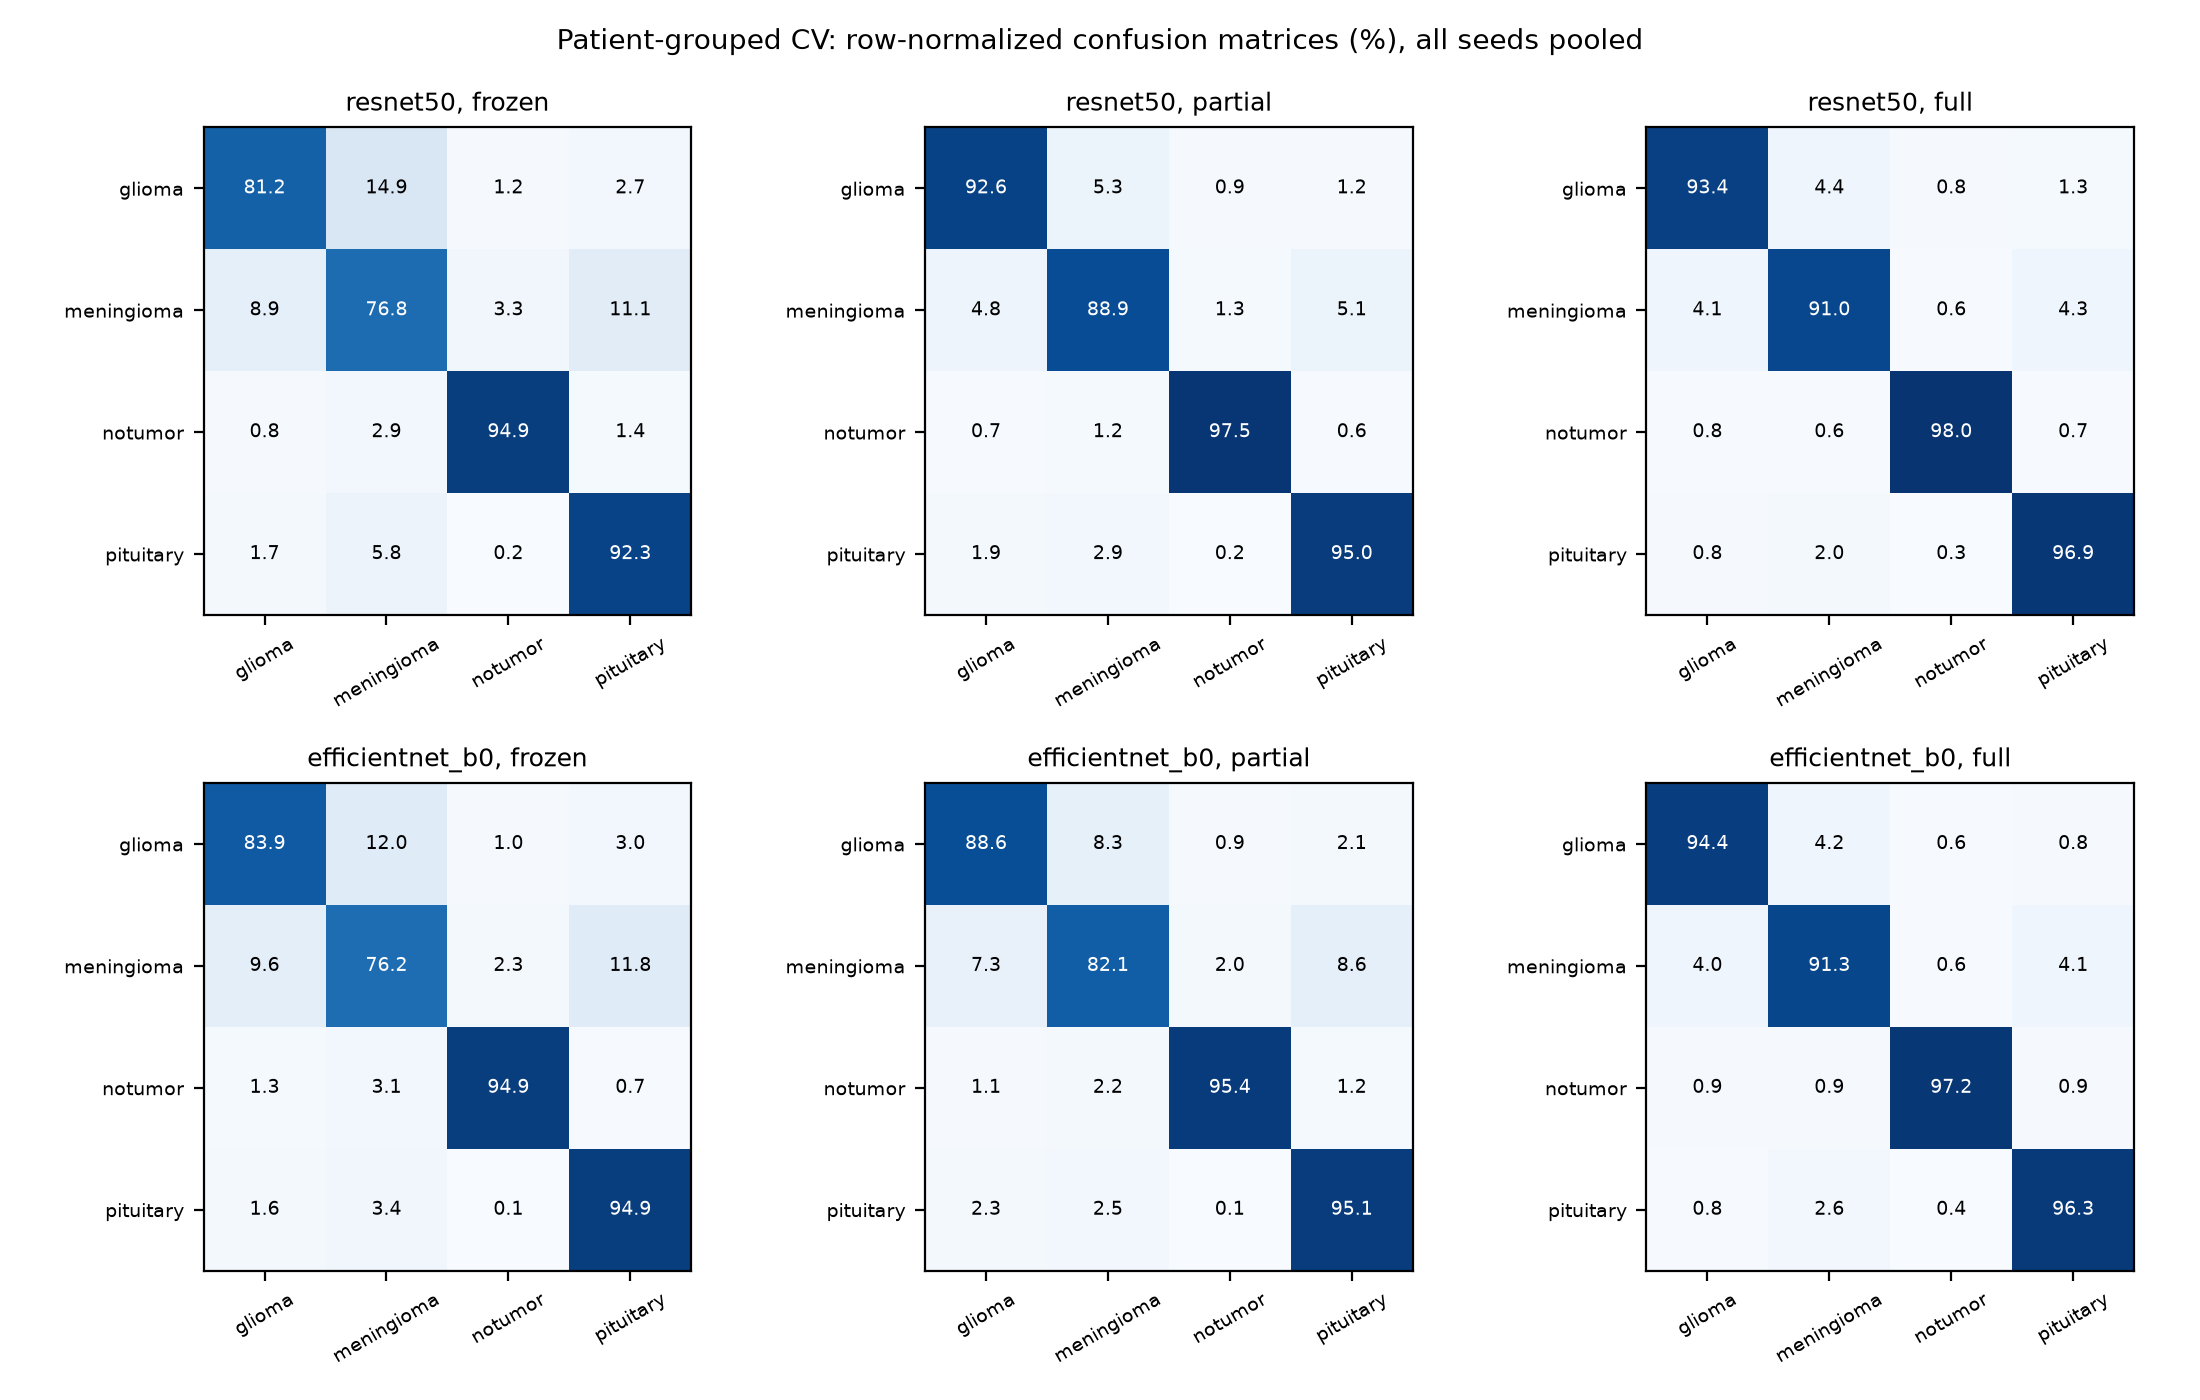

In [35]:
display(summary[summary.protocol == "grouped"][["arch", "depth"] + [f"rec_{c}_mean" for c in CLASSES]].round(4))
display(ShowImage(str(FIGS / "fig_confusion_grouped.png")))

### 6.4 Control: traceable vs. untraceable images
accuracy on the traceable and untraceable subsets under random and grouped CV, and the gap between them.

In [36]:
display(traceable_table.round(4))

protocol,arch,depth,subset,grouped,random,gap
0,efficientnet_b0,frozen,traceable,0.8685,0.9041,0.0357
1,efficientnet_b0,frozen,untraceable,0.8877,0.9142,0.0264
2,efficientnet_b0,full,traceable,0.9490,0.9905,0.0415
3,efficientnet_b0,full,untraceable,0.9459,0.9755,0.0296
4,efficientnet_b0,partial,traceable,0.9016,0.9809,0.0793
5,efficientnet_b0,partial,untraceable,0.9066,0.9670,0.0605
6,resnet50,frozen,traceable,0.8551,0.8837,0.0285
7,resnet50,frozen,untraceable,0.8789,0.9004,0.0216
8,resnet50,full,traceable,0.9482,0.9905,0.0423
9,resnet50,full,untraceable,0.9482,0.9700,0.0218


## 7. RQ3: Grad-CAM against expert tumor masks

### Recover the expert tumor mask of each traceable image

The figshare dataset contains, for 3,064 MRI slices, the image, the **tumor outline drawn by experts** (mask) and
the patient ID, stored as MATLAB `.mat` files. Many Kaggle glioma/meningioma/pituitary images are copies of
these slices (resized, sometimes rotated or flipped), but the group file tells only the *patient*, not the
*slice*. This code finds the matching slice for every traceable Kaggle image and brings its mask into the
224×224 frame of our preprocessed image.

**Matching method: normalized cross-correlation (NCC)**, i.e. the Pearson correlation between two images'
pixel values (1 = identical up to brightness/contrast). It is computed on small 64×64 thumbnails, against
all slices of the same patient, in **all 8 orientations** (4 rotations × with/without mirroring).


**Sources / further reading**
- [Cheng et al., *Enhanced Performance of Brain Tumor Classification via Tumor Region Augmentation and Partition*, PLoS ONE 2015](https://doi.org/10.1371/journal.pone.0140381); dataset: [figshare 1512427](https://doi.org/10.6084/m9.figshare.1512427), CC BY 4.0
- [Lewis, *Fast Normalized Cross-Correlation*, Vision Interface 1995](https://scribblethink.org/Work/nvisionInterface/nip.html)
- [h5py documentation](https://docs.h5py.org/en/stable/) — MATLAB v7.3 `.mat` files are HDF5 files ([background](https://mloss-static.ml.tu-berlin.de/community/blog/2009/nov/19/matlabtm-73-file-format-is-actually-hdf5-and-can-b/index.html))

`THUMB = 64` is the thumbnail size and `MIN_NCC = 0.90` the minimum correlation accepted as a match.

**`orient(a, o)`** — one of the 8 orientations of a square image: `o % 4` quarter-turns with `np.rot90`, and for
`o >= 4` additionally a left-right mirror (`a[..., ::-1]`). These 8 are all the ways to rotate/flip a square
(mathematically, the *dihedral group* of the square). Works on a single image or a stack (last two axes).

**`unit_vectors(a)`** — flatten each image to a vector, subtract its mean and divide by its length (L2 norm).
After this, the dot product of two such vectors **is** their normalized cross-correlation. This trick turns
"compare one image with thousands of slices in 8 orientations" into a single matrix multiplication.

**`norm_pid(s)`** — clean a patient ID for comparison: remove every character that is not a letter or digit
(regular expression `[^0-9A-Za-z]`) and convert to upper case, so `"mr-0012 "` and `"MR0012"` compare equal.

In [37]:
THUMB = 64
MIN_NCC = 0.90


def orient(a, o):
    """One of the 8 rotations/reflections of the last two axes."""
    a = np.rot90(a, o % 4, axes=(-2, -1))
    return a[..., ::-1] if o >= 4 else a


def unit_vectors(a):
    a = a.reshape(len(a), -1).astype(np.float32)
    a = a - a.mean(1, keepdims=True)
    return a / np.maximum(np.linalg.norm(a, axis=1, keepdims=True), 1e-8)


def norm_pid(s):
    return re.sub(r"[^0-9A-Za-z]", "", str(s)).upper()

**`load_figshare()`** — read all figshare slices and return their 64×64 thumbnails, patient IDs and file
paths.

1. Find all `.mat` files whose name is a number, sorted numerically (`key=(len(stem), stem)` sorts "2" before "10").
2. Each file is a **MATLAB v7.3 file, which is internally an HDF5 file**, so it is opened with `h5py`. Inside, the
   struct `cjdata` has fields `image`, `PID` (patient ID stored as character codes, turned back into text with
   `chr`) and `tumorMask`.
3. Normalize each image to [0, 1] (min–max), make a 64×64 thumbnail, and normalize the patient ID with `norm_pid`.
4. Print the number of slices and patients (expected 3064 and 233).

**`read_mask(path)`** — read only the expert tumor mask (`cjdata/tumorMask`) of one `.mat` file as a True/False
array; used for the matched slices only.


**Sources / further reading**
- [h5py documentation](https://docs.h5py.org/en/stable/) — MATLAB v7.3 `.mat` files are HDF5 files ([background](https://mloss-static.ml.tu-berlin.de/community/blog/2009/nov/19/matlabtm-73-file-format-is-actually-hdf5-and-can-b/index.html))

In [38]:
def load_figshare():
    files = sorted(FIGSHARE_DIR.rglob("*.mat"), key=lambda p: (len(p.stem), p.stem))
    files = [f for f in files if f.stem.isdigit()]
    thumbs, pids = [], []
    for f in files:
        with h5py.File(f, "r") as h:
            cjdata = h["cjdata"]
            img = np.array(cjdata["image"], dtype=np.float32)
            pid = "".join(chr(int(c)) for c in np.array(cjdata["PID"]).flatten())
        img = (img - img.min()) / max(float(img.max() - img.min()), 1e-6)
        thumbs.append(np.asarray(Image.fromarray((img * 255).astype(np.uint8)).resize((THUMB, THUMB), Image.BILINEAR)))
        pids.append(norm_pid(pid))
    print(f"figshare slices: {len(files)} | patients: {len(set(pids))}")
    return np.stack(thumbs), np.array(pids), np.array([str(f) for f in files])


def read_mask(path):
    """The expert tumor mask of one .mat file as a True/False array."""
    with h5py.File(path, "r") as h:
        return np.array(h["cjdata"]["tumorMask"]) > 0

**`match_masks()`** returns `(mask_table, masks)`:

1. Load the figshare thumbnails; precompute the unit vectors of all slices in all 8 orientations
   (`slices_all_orient`, array 8 × N × 4096).
2. For every traceable Kaggle image: make its 64×64 thumbnail from the **original** file, find the slices of the
   same patient (`candidates`; if the patient is not found, search all slices), and compute all NCC values with one
   matrix product; take the best (orientation, slice).
3. If NCC ≥ 0.90: read that slice's mask, apply the same orientation, resize it to the original Kaggle image size,
   apply the **same crop box** as the image preprocessing, and resize to 224×224. Nearest-neighbour resizing keeps
   the mask strictly 0/1. If no tumor pixel is left after cropping, the image counts as not matched.
4. `masks` holds all masks (N × 224 × 224); `mask_table` has one row per traceable image with the match details,
   and for matched images `mask_pos`, the position of its mask in `masks`. The cell prints the match count, the
   median NCC, the orientation counts and the mean tumor share of the image (the chance level for RQ3).


In [39]:
def match_masks():
    thumbs, pids, files = load_figshare()
    slices_all_orient = np.stack([unit_vectors(orient(thumbs, o)) for o in range(8)])   # 8 x N x THUMB*THUMB
    rows, masks = [], []
    for idx, r in index_df[index_df.traceable].iterrows():
        gray = np.asarray(Image.open(KAGGLE_DIR / r.rel).convert("L"))
        kaggle_vec = unit_vectors(np.asarray(Image.fromarray(gray).resize((THUMB, THUMB), Image.BILINEAR))[None])[0]
        candidates = np.where(pids == norm_pid(r.patient_id))[0]
        same_patient = len(candidates) > 0
        if not same_patient:
            candidates = np.arange(len(pids))
        ncc = slices_all_orient[:, candidates, :] @ kaggle_vec                          # 8 x n_candidates
        orientation, slice_pos = np.unravel_index(int(ncc.argmax()), ncc.shape)
        best_ncc = float(ncc[orientation, slice_pos])
        fig_file = files[candidates[slice_pos]]
        row = dict(idx=idx, rel=r.rel, fig_file=fig_file, orientation=int(orientation), ncc=best_ncc,
                   patient_restricted=same_patient, matched=best_ncc >= MIN_NCC)
        if row["matched"]:
            mask = orient(read_mask(fig_file), int(orientation))
            mask = Image.fromarray((mask * 255).astype(np.uint8)).resize((int(r.width), int(r.height)), Image.NEAREST)
            mask = mask.crop((int(r.x0), int(r.y0), int(r.x1), int(r.y1))).resize((IMG, IMG), Image.NEAREST)
            mask = np.asarray(mask) > 127
            row["mask_frac"] = float(mask.mean())
            row["matched"] = bool(mask.any())
            if row["matched"]:
                row["mask_pos"] = len(masks)
                masks.append(mask)
        rows.append(row)
    mask_table = pd.DataFrame(rows)
    print(f"traceable images: {len(mask_table)} | matched with a mask: {int(mask_table.matched.sum())} "
          f"| median NCC: {mask_table.ncc.median():.3f} | NCC < {MIN_NCC}: {int((mask_table.ncc < MIN_NCC).sum())}")
    print("orientation counts:", mask_table[mask_table.matched].orientation.value_counts().sort_index().to_dict())
    print(f"mean tumor share of image area (chance level): {mask_table.mask_frac.mean():.4f}")
    return mask_table, np.stack(masks)


mask_table, masks = match_masks()

figshare slices: 3064 | patients: 233


traceable images: 4835 | matched with a mask: 4835 | median NCC: 1.000 | NCC < 0.9: 0
orientation counts: {1: 2, 3: 3041, 5: 2, 7: 1790}
mean tumor share of image area (chance level): 0.0253


**overlay check.** Ten matched images (drawn with a fixed seed: `sample(10, random_state=0)`) with the expert
mask outline in cyan (`contour` at level 0.5 draws the border between 0 and 1). The outline should sit on the
tumor, also for images whose match needed a rotation or flip (`orient` != 0).

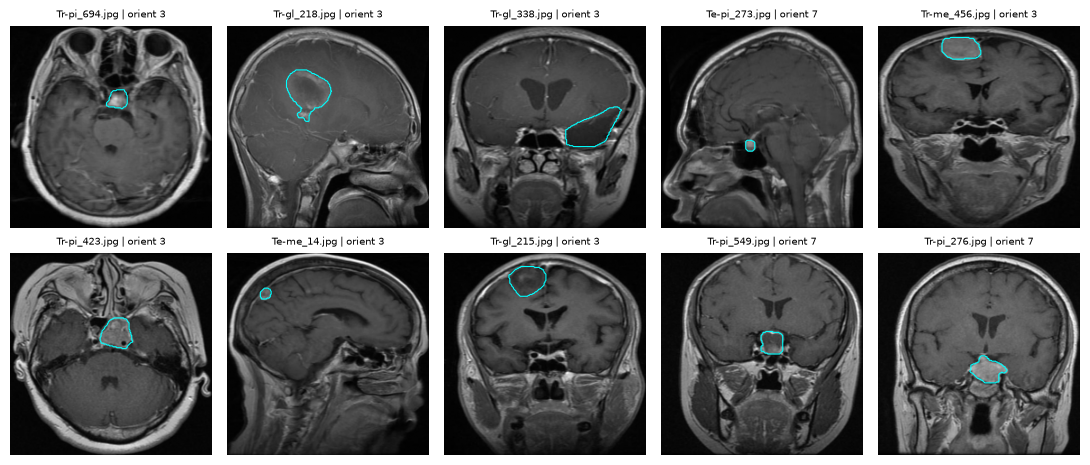

In [40]:
matched = mask_table[mask_table.matched]
fig, axes = plt.subplots(2, 5, figsize=(11, 4.8))
for ax, (_, r) in zip(axes.ravel(), matched.sample(10, random_state=0).iterrows()):
    ax.imshow(images[int(r.idx)], cmap="gray")
    ax.contour(masks[int(r.mask_pos)], levels=[0.5], colors="cyan", linewidths=0.8)
    ax.set_title(f"{r.rel.split('/')[-1]} | orient {r.orientation}", fontsize=7); ax.axis("off")
plt.tight_layout(); plt.show()

### Where does the network look? (RQ3)

**Grad-CAM** produces a heatmap of the image regions that most increased the score of the predicted class:
1. take the feature maps `A_k` of the last convolutional stage (7×7 maps, one per channel k);
2. compute the gradient of the class score with respect to these maps and average it over the 7×7 positions ->
   one importance weight `w_k` per channel;
3. heatmap = ReLU(Σ_k w_k · A_k), upsampled to 224×224.

Two scores compare the heatmap with the expert mask:
- **pointing game** (`hit`): is the hottest pixel of the heatmap inside the tumor?
- **energy share** (`energy`): which fraction of the total heatmap lies inside the tumor?

The chance level of both is the tumor's share of the image area (`mask_frac`): a heatmap that points at a random
place hits the tumor that often. Grad-CAM shows where evidence is concentrated; it is not a segmentation.


**Sources / further reading**
- [Selvaraju et al., *Grad-CAM: Visual Explanations from Deep Networks via Gradient-based Localization*, ICCV 2017 (arXiv:1610.02391)](https://arxiv.org/abs/1610.02391)
- [Zhang et al., *Top-down Neural Attention by Excitation Backprop*, ECCV 2016 / IJCV 2018 (arXiv:1608.00507)](https://arxiv.org/abs/1608.00507) — introduces the *pointing game*
- [Wang et al., *Score-CAM*, CVPR Workshops 2020 (arXiv:1910.01279)](https://arxiv.org/abs/1910.01279) — introduces the *energy-based* pointing game (share of heatmap energy inside the object)

**`grad_cam(model, batch)`** — Grad-CAM for a batch; returns the heatmaps (B × 224 × 224) and the predicted classes.

1. **Forward hook.** `register_forward_hook` attaches a small function to the CAM layer that runs every time the
   layer produces its output; here it simply stores that output (`store["act"]`). Hooks let us read inner
   activations without changing the model code. The hook is removed afterwards (`hook.remove()`).
2. `batch.clone().requires_grad_(True)` — a trick: when the backbone is frozen, no weight requires a gradient, so PyTorch would
   not record the computation graph; making the *input* require gradients forces it to.
3. Forward pass, predicted class = argmax of the logits; the score is the sum of each image's predicted-class logit.
   Summing is fine because in eval mode the images in a batch do not influence each other, so the gradient of the
   sum with respect to image i's activations is exactly the gradient of image i's own score.
4. `torch.autograd.grad(score, activations)` returns the gradient directly (instead of `.backward()`, which would
   store gradients on the weights).
5. Channel weights = mean gradient over the 7×7 positions; heatmap = ReLU of the weighted sum of channels;
   `F.interpolate` (bilinear) scales 7×7 up to 224×224.


**Sources / further reading**
- [PyTorch: `Module.register_forward_hook`](https://docs.pytorch.org/docs/stable/generated/torch.nn.Module.html#torch.nn.Module.register_forward_hook)
- [PyTorch: `torch.autograd.grad`](https://pytorch.org/docs/stable/generated/torch.autograd.grad)

In [41]:
def grad_cam(model, batch):
    """Returns (cam B x H x W in [0, inf), predicted class B)."""
    store = {}
    hook = cam_layer(model).register_forward_hook(lambda module, inputs, output: store.update(act=output))
    batch = batch.clone().requires_grad_(True)       # keeps a graph even when the backbone is frozen
    with torch.enable_grad():
        logits = model(batch)
        pred = logits.argmax(1)
        score = logits.gather(1, pred[:, None]).sum()
        grads = torch.autograd.grad(score, store["act"])[0]
    hook.remove()
    channel_weights = grads.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((channel_weights * store["act"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=batch.shape[-2:], mode="bilinear", align_corners=False)[:, 0]
    return cam.detach(), pred.detach()

**`gradcam_all(mask_table, masks)`** — for every grouped-CV run (2 architectures × 3 depths × 2 seeds × 5 folds =
60 models):

1. Load the saved weights, recreate the same test fold with `get_split`, keep the test images that have a mask
   (`mask_pos_of` maps an image position to the position of its mask).
2. In batches of 64: compute Grad-CAM; `hit` = mask value at the heatmap's maximum (`argmax` on the flattened map,
   `gather` picks that pixel from the mask); `energy` = heatmap sum inside the mask / total heatmap sum.
3. A heatmap that is zero everywhere ("empty CAM") gets hit = 0 and energy = NaN (not a number) and is counted.
4. Print one progress line per model (`done <run name> <number of images>`), save one row per image and model
   (`results/tables/rq3_gradcam_per_image.csv`) and return the table.

Every image is scored only by models that did **not** see its group during training.

In [42]:
def gradcam_all(mask_table, masks):
    matched = mask_table[mask_table.matched]
    mask_pos_of = dict(zip(matched.idx.astype(int), matched.mask_pos.astype(int)))
    masks_gpu = torch.from_numpy(masks).to(device)
    labels = index_df["label"].to_numpy()
    group_of = index_df["group_id"].to_numpy()
    rows = []
    for arch in ARCHS:
        for depth in DEPTHS:
            for seed in SEEDS["grouped"]:
                for fold in range(N_FOLDS):
                    name = run_name("grouped", arch, depth, seed, fold)
                    _, _, test_idx = get_split(index_df, "grouped", seed, fold)
                    test_idx = np.array([i for i in test_idx if i in mask_pos_of])
                    model = build_model(arch, depth).to(device)
                    model.load_state_dict(torch.load(CHECKPOINTS / f"{name}.pt", map_location=device))
                    model.eval()
                    for start in range(0, len(test_idx), 64):
                        batch_idx = test_idx[start:start + 64]
                        cam, pred = grad_cam(model, to_input(x_all[torch.as_tensor(batch_idx, device=device)]))
                        mask = masks_gpu[torch.as_tensor([mask_pos_of[i] for i in batch_idx], device=device)]
                        cam_flat = cam.flatten(1)
                        hit = mask.flatten(1).gather(1, cam_flat.argmax(1, keepdim=True))[:, 0]
                        cam_total = cam_flat.sum(1)
                        energy = (cam * mask).flatten(1).sum(1) / cam_total.clamp_min(1e-12)
                        for j, i in enumerate(batch_idx):
                            empty = bool(cam_total[j] <= 0)
                            rows.append(dict(arch=arch, depth=depth, seed=seed, fold=fold, idx=int(i),
                                             group_id=int(group_of[i]), label=int(labels[i]), pred=int(pred[j]),
                                             correct=bool(pred[j] == labels[i]),
                                             hit=0.0 if empty else float(hit[j]),
                                             energy=float("nan") if empty else float(energy[j]),
                                             mask_frac=float(mask[j].float().mean()), empty_cam=empty))
                    print("done", name, len(test_idx), flush=True)
    gradcam_rows = pd.DataFrame(rows)
    gradcam_rows.to_csv(TABLES / "rq3_gradcam_per_image.csv", index=False)
    return gradcam_rows

**`boot_ci(g, col, rng)`** — 95 % group-bootstrap interval for a mean (e.g. the hit rate): sum and count per group,
multinomial resampling weights over groups (as in `delta_table`), mean = weighted sum / weighted count per resample,
then the 2.5th and 97.5th percentiles.

**`gradcam_summary(gradcam_rows)`** — the RQ3 summary per architecture and depth for all images, correctly
classified images and misclassified images: number of images, pointing-game hit rate with its interval, mean energy
share, chance level and number of empty heatmaps.


**Sources / further reading**
- [Efron & Tibshirani, *An Introduction to the Bootstrap*, Chapman & Hall 1993](https://www.routledge.com/An-Introduction-to-the-Bootstrap/Efron-Tibshirani/p/book/9780412042317) — the percentile interval
- [Field & Welsh, *Bootstrapping clustered data*, J. R. Stat. Soc. B 69(3), 2007](https://doi.org/10.1111/j.1467-9868.2007.00593.x) — resampling whole clusters (here: whole image groups)

In [43]:
def boot_ci(g, col, rng):
    """95% interval for a mean, resampling whole groups."""
    sum_count = g.groupby("group_id")[col].agg(["sum", "count"]).to_numpy()
    n_groups = len(sum_count)
    boot_weights = rng.multinomial(n_groups, np.full(n_groups, 1 / n_groups), size=N_BOOT)
    values = (boot_weights @ sum_count[:, 0]) / np.maximum(boot_weights @ sum_count[:, 1], 1e-9)
    return np.percentile(values, 2.5), np.percentile(values, 97.5)


def gradcam_summary(gradcam_rows):
    rng = np.random.default_rng(0)
    rows = []
    R = gradcam_rows
    for subset, selection in (("all", R), ("correct", R[R.correct]), ("incorrect", R[~R.correct])):
        for (arch, depth), g in selection.groupby(["arch", "depth"]):
            lo, hi = boot_ci(g, "hit", rng)
            rows.append(dict(arch=arch, depth=depth, subset=subset, n=len(g), pointing_hit_rate=g.hit.mean(),
                             hit_ci_lo=lo, hit_ci_hi=hi, energy_in_mask=g.energy.dropna().mean(),
                             chance_level=g.mask_frac.mean(), empty_cams=int(g.empty_cam.sum())))
    return pd.DataFrame(rows)

**run Grad-CAM for all 60 grouped-CV models** (a few minutes), save the summary as
`results/tables/rq3_gradcam_summary.csv` and show it. Compare `pointing_hit_rate` and
`energy_in_mask` with `chance_level`.

In [44]:
gradcam_rows = gradcam_all(mask_table, masks)
rq3_summary = gradcam_summary(gradcam_rows)
rq3_summary.to_csv(TABLES / "rq3_gradcam_summary.csv", index=False)
display(rq3_summary.round(4))

done grouped__resnet50__frozen__s0__f0 972


done grouped__resnet50__frozen__s0__f1 975


done grouped__resnet50__frozen__s0__f2 971


done grouped__resnet50__frozen__s0__f3 957


done grouped__resnet50__frozen__s0__f4 960


done grouped__resnet50__frozen__s1__f0 966


... (51 outputs left out)

done grouped__efficientnet_b0__full__s1__f2 979


done grouped__efficientnet_b0__full__s1__f3 965


done grouped__efficientnet_b0__full__s1__f4 955


,arch,depth,subset,n,pointing_hit_rate,hit_ci_lo,hit_ci_hi,energy_in_mask,chance_level,empty_cams
0,efficientnet_b0,frozen,all,9670,0.1156,0.0961,0.1353,0.0413,0.0253,0
1,efficientnet_b0,full,all,9670,0.3397,0.2920,0.3870,0.1174,0.0253,0
2,efficientnet_b0,partial,all,9670,0.2367,0.1993,0.2778,0.0722,0.0253,0
3,resnet50,frozen,all,9670,0.0736,0.0582,0.0889,0.0365,0.0253,0
4,resnet50,full,all,9670,0.1674,0.1419,0.1949,0.0602,0.0253,0
5,resnet50,partial,all,9670,0.1871,0.1563,0.2206,0.0589,0.0253,0
6,efficientnet_b0,frozen,correct,8398,0.1222,0.1008,0.1458,0.0430,0.0251,0
7,efficientnet_b0,full,correct,9177,0.3438,0.2958,0.3969,0.1191,0.0256,0
8,efficientnet_b0,partial,correct,8718,0.2517,0.2097,0.2944,0.0755,0.0256,0
9,resnet50,frozen,correct,8269,0.0797,0.0622,0.0980,0.0382,0.0251,0


## 8. Exploratory analyses and Grad-CAM examples

### Extra analyses, added after the main results were seen


**`group_cm(preds, protocol, arch, depth, seed)`** — one 4×4 confusion matrix **per group** (array G × 4 × 4) for one
configuration, built with `np.add.at`.

**`cm_stats(cm)`** — recall per class, balanced accuracy and macro-F1 from confusion matrices with any number of
leading dimensions (`...` in NumPy indexing), so one call handles a single matrix or 2000 bootstrap matrices.
`np.diagonal(cm, axis1=-2, axis2=-1)` takes the diagonal of the last two axes.

**`ci(x)`** — 2.5th and 97.5th percentiles along the first axis: the 95 % percentile interval.


**Sources / further reading**
- [NumPy: `ufunc.at` (e.g. `np.add.at`)](https://numpy.org/doc/stable/reference/generated/numpy.ufunc.at.html)

In [45]:
def group_cm(preds, protocol, arch, depth, seed):
    """Confusion matrix per group: array (G, K, K) with rows = true class."""
    g = preds[(preds.protocol == protocol) & (preds.arch == arch) & (preds.depth == depth) & (preds.seed == seed)]
    codes, unique_groups = pd.factorize(index_df["group_id"].to_numpy()[g.idx.to_numpy()], sort=True)
    cm = np.zeros((len(unique_groups), K, K))
    np.add.at(cm, (codes, g.label.to_numpy(), g.pred.to_numpy()), 1)
    return cm


def cm_stats(cm):
    """cm: (..., K, K) -> dict of recall (..., K), balanced accuracy and macro-F1 (...)."""
    tp = np.diagonal(cm, axis1=-2, axis2=-1)
    recall = tp / np.maximum(cm.sum(-1), 1e-9)
    precision = tp / np.maximum(cm.sum(-2), 1e-9)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    return dict(rec=recall, bacc=recall.mean(-1), f1=f1.mean(-1))


def ci(x):
    return np.percentile(x, 2.5, axis=0), np.percentile(x, 97.5, axis=0)

**`classification(preds)`** — group-bootstrap intervals for:
1. **RQ2 contrasts** under grouped CV: full − frozen, partial − frozen, full − partial, for balanced accuracy and
   macro-F1;
2. the **error ratio** (1 − bacc_grouped)/(1 − bacc_random) per depth, and its contrasts between depths;
3. the **recall gap per class** (random minus grouped recall).

For every seed, `res[(protocol, depth)]` holds the point estimate (`"point"`, all groups once) and the 2000
bootstrap values (`"boot"`). The bootstrap confusion matrices are formed in one step with
`np.einsum("bg,gkl->bkl", boot_weights, cm)`: for every bootstrap sample b, the weighted sum over groups g of the
group matrices. `einsum` ("Einstein summation") writes such multi-axis products in one line. The inner function
`average_over_seeds` averages point estimates and interval end points over seeds, as in `delta_table`;
`error_ratio` computes the error ratio from either the point or the bootstrap values.


**Sources / further reading**
- [NumPy: `einsum`](https://numpy.org/doc/stable/reference/generated/numpy.einsum.html)
- [Field & Welsh, *Bootstrapping clustered data*, J. R. Stat. Soc. B 69(3), 2007](https://doi.org/10.1111/j.1467-9868.2007.00593.x) — resampling whole clusters (here: whole image groups)

In [46]:
def classification(preds):
    rng = np.random.default_rng(1)
    rq2, ratio, ratio_contrasts, per_class = [], [], [], []
    for arch in ARCHS:
        seeds = []
        for seed in SEEDS["grouped"]:
            group_cms = {(protocol, depth): group_cm(preds, protocol, arch, depth, seed)
                         for protocol in ("random", "grouped") for depth in DEPTHS}
            n_groups = group_cms[("grouped", "frozen")].shape[0]
            boot_weights = rng.multinomial(n_groups, np.full(n_groups, 1 / n_groups), size=N_BOOT).astype(float)
            res = {}
            for key, cm in group_cms.items():
                res[key] = dict(point=cm_stats(cm.sum(0)), boot=cm_stats(np.einsum("bg,gkl->bkl", boot_weights, cm)))
            seeds.append(res)

        def average_over_seeds(point_fn, boot_fn):
            estimate = np.mean([point_fn(r) for r in seeds], axis=0)
            lo = np.mean([ci(boot_fn(r))[0] for r in seeds], axis=0)
            hi = np.mean([ci(boot_fn(r))[1] for r in seeds], axis=0)
            return estimate, lo, hi

        for metric in ("bacc", "f1"):
            for deeper, shallower in DEPTH_PAIRS:
                e, lo, hi = average_over_seeds(
                    lambda r: r[("grouped", deeper)]["point"][metric] - r[("grouped", shallower)]["point"][metric],
                    lambda r: r[("grouped", deeper)]["boot"][metric] - r[("grouped", shallower)]["boot"][metric])
                rq2.append(dict(arch=arch, metric={"bacc": "balanced accuracy", "f1": "macro-F1"}[metric],
                                contrast=f"{deeper} - {shallower}", estimate=e, ci_lo=lo, ci_hi=hi,
                                excludes_zero=bool(lo > 0 or hi < 0)))

        def error_ratio(r, depth, which):
            return (1 - r[("grouped", depth)][which]["bacc"]) / np.maximum(1 - r[("random", depth)][which]["bacc"], 1e-9)

        for depth in DEPTHS:
            e, lo, hi = average_over_seeds(lambda r: error_ratio(r, depth, "point"), lambda r: error_ratio(r, depth, "boot"))
            ratio.append(dict(arch=arch, depth=depth, error_ratio=e, ci_lo=lo, ci_hi=hi))
            for k, cls in enumerate(CLASSES):
                e, lo, hi = average_over_seeds(
                    lambda r: r[("random", depth)]["point"]["rec"][k] - r[("grouped", depth)]["point"]["rec"][k],
                    lambda r: r[("random", depth)]["boot"]["rec"][:, k] - r[("grouped", depth)]["boot"]["rec"][:, k])
                per_class.append(dict(arch=arch, depth=depth, cls=cls, recall_gap=e, ci_lo=lo, ci_hi=hi))
        for deeper, shallower in DEPTH_PAIRS:
            e, lo, hi = average_over_seeds(
                lambda r: error_ratio(r, deeper, "point") - error_ratio(r, shallower, "point"),
                lambda r: error_ratio(r, deeper, "boot") - error_ratio(r, shallower, "boot"))
            ratio_contrasts.append(dict(arch=arch, contrast=f"ratio({deeper}) - ratio({shallower})", estimate=e,
                                        ci_lo=lo, ci_hi=hi, excludes_zero=bool(lo > 0 or hi < 0)))
    return pd.DataFrame(rq2), pd.DataFrame(ratio), pd.DataFrame(ratio_contrasts), pd.DataFrame(per_class)

**`reliability(preds)`** — **reliability curves** for full fine-tuning: for each confidence bin (≥ 20 predictions),
accuracy vs. mean confidence, under random and grouped CV. A calibrated model lies on the diagonal; points below
the diagonal mean over-confidence.


**Sources / further reading**
- [Guo et al., *On Calibration of Modern Neural Networks*, ICML 2017 (arXiv:1706.04599)](https://arxiv.org/abs/1706.04599)

In [47]:
def reliability(preds):
    edges = np.linspace(0, 1, ECE_BINS + 1)
    fig, axes = plt.subplots(1, len(ARCHS), figsize=(9, 4), sharey=True)
    for ax, arch in zip(axes, ARCHS):
        ax.plot([0, 1], [0, 1], color="gray", lw=0.8, ls=":")
        for protocol, style in (("random", "o-"), ("grouped", "s--")):
            g = preds[(preds.protocol == protocol) & (preds.arch == arch) & (preds.depth == "full")]
            probs = g[PROB_COLS].to_numpy()
            confidence, correct = probs.max(1), (probs.argmax(1) == g.label.to_numpy())
            bin_of = np.clip(np.digitize(confidence, edges[1:-1], right=True), 0, ECE_BINS - 1)
            xs = [confidence[bin_of == b].mean() for b in range(ECE_BINS) if (bin_of == b).sum() >= 20]
            ys = [correct[bin_of == b].mean() for b in range(ECE_BINS) if (bin_of == b).sum() >= 20]
            ax.plot(xs, ys, style, ms=4, label=f"{protocol} CV")
        ax.set_title(f"{arch}, full fine-tuning", fontsize=10)
        ax.set_xlabel("confidence")
        ax.set_xlim(0.3, 1.02)
        ax.set_ylim(0.3, 1.02)
    axes[0].set_ylabel("accuracy")
    axes[0].legend(fontsize=8)
    fig.suptitle("Reliability curves (bins with at least 20 predictions; all folds and seeds pooled)", fontsize=10)
    fig.tight_layout()
    fig.savefig(FIGS / "fig_reliability_full.png", dpi=200)
    plt.close(fig)

**`rq3_breakdowns(gradcam_rows, rq3_summary)`** — RQ3 breakdowns from the Grad-CAM per-image table: the difference in hit rate between correctly
and incorrectly classified images with a group-bootstrap interval (computed as a ratio of weighted sums per
resample), the per-class hit rate and energy share, and the figure `results/figures/fig_rq3_pointing.png` (hit rate per depth with
intervals and the chance line).

In [48]:
def rq3_breakdowns(gradcam_rows, rq3_summary):
    rng = np.random.default_rng(2)
    diff_rows, class_rows = [], []
    for (arch, depth), g in gradcam_rows.groupby(["arch", "depth"]):
        s = g.assign(c=g.correct.astype(float), hit_correct=g.hit * g.correct, hit_incorrect=g.hit * (~g.correct))
        per_group = s.groupby("group_id").agg(n=("hit", "size"), c=("c", "sum"), hc=("hit_correct", "sum"),
                                              hi=("hit_incorrect", "sum")).to_numpy()
        n_groups = len(per_group)
        boot_weights = rng.multinomial(n_groups, np.full(n_groups, 1 / n_groups), size=N_BOOT).astype(float)
        n_images, n_correct, hits_correct, hits_incorrect = (boot_weights @ per_group[:, j] for j in range(4))
        boot = hits_correct / np.maximum(n_correct, 1e-9) - hits_incorrect / np.maximum(n_images - n_correct, 1e-9)
        estimate = g[g.correct].hit.mean() - g[~g.correct].hit.mean()
        lo, hi = ci(boot)
        diff_rows.append(dict(arch=arch, depth=depth, hit_correct=g[g.correct].hit.mean(),
                              hit_incorrect=g[~g.correct].hit.mean(), difference=estimate, ci_lo=lo, ci_hi=hi,
                              excludes_zero=bool(lo > 0 or hi < 0)))
        for k, cls in enumerate(CLASSES):
            q = g[g.label == k]
            if len(q):
                class_rows.append(dict(arch=arch, depth=depth, cls=cls, n=len(q), pointing_hit_rate=q.hit.mean(),
                                       energy_in_mask=q.energy.mean(), chance_level=q.mask_frac.mean()))

    S = rq3_summary[rq3_summary.subset == "all"]
    xs = np.arange(len(DEPTHS))
    fig, axes = plt.subplots(1, len(ARCHS), figsize=(9, 3.6), sharey=True)
    for ax, arch in zip(axes, ARCHS):
        d = S[S.arch == arch].set_index("depth").reindex(DEPTHS)
        ax.bar(xs, 100 * d.pointing_hit_rate, color="#55A868", width=0.6)
        ax.errorbar(xs, 100 * d.pointing_hit_rate,
                    yerr=[100 * (d.pointing_hit_rate - d.hit_ci_lo), 100 * (d.hit_ci_hi - d.pointing_hit_rate)],
                    fmt="none", ecolor="black", capsize=4)
        ax.axhline(100 * d.chance_level.mean(), color="red", ls="--", lw=1, label="chance (tumor share of image)")
        ax.set_xticks(xs, DEPTHS)
        ax.set_title(arch)
        ax.set_xlabel("fine-tuning depth")
    axes[0].set_ylabel("pointing-game hit rate (%)")
    axes[0].legend(fontsize=8)
    fig.suptitle("Grad-CAM maximum inside the expert tumor mask (95% group-bootstrap CI)", fontsize=10)
    fig.tight_layout()
    fig.savefig(FIGS / "fig_rq3_pointing.png", dpi=200)
    plt.close(fig)
    return pd.DataFrame(diff_rows), pd.DataFrame(class_rows)

**run the exploratory analyses**, save the `expl_*.csv` tables in `results/tables/` (RQ2 contrasts, error ratios and their
contrasts, recall gap per class, ECE by protocol with the grouped/random ratio, RQ3 breakdowns), show them, and show
the reliability curves and the RQ3 pointing-game figure.

== expl_rq2_contrasts ==


,arch,metric,contrast,estimate,ci_lo,ci_hi,excludes_zero
0,resnet50,balanced accuracy,full - frozen,0.0853,0.0709,0.1009,True
1,resnet50,balanced accuracy,partial - frozen,0.0719,0.0587,0.0862,True
2,resnet50,balanced accuracy,full - partial,0.0133,0.0050,0.0225,True
3,resnet50,macro-F1,full - frozen,0.0856,0.0716,0.1013,True
4,resnet50,macro-F1,partial - frozen,0.0722,0.0592,0.0867,True
5,resnet50,macro-F1,full - partial,0.0133,0.0049,0.0226,True
6,efficientnet_b0,balanced accuracy,full - frozen,0.0732,0.0592,0.0880,True
7,efficientnet_b0,balanced accuracy,partial - frozen,0.0284,0.0176,0.0394,True
8,efficientnet_b0,balanced accuracy,full - partial,0.0448,0.0326,0.0577,True
9,efficientnet_b0,macro-F1,full - frozen,0.0741,0.0600,0.0898,True


== expl_error_ratio ==


,arch,depth,error_ratio,ci_lo,ci_hi
0,resnet50,frozen,1.2399,1.1608,1.3295
1,resnet50,partial,3.4951,2.7272,4.5156
2,resnet50,full,3.2079,2.4500,4.2267
3,efficientnet_b0,frozen,1.3526,1.2444,1.4739
4,efficientnet_b0,partial,4.0984,3.3062,5.1068
5,efficientnet_b0,full,3.6216,2.6628,4.8997


== expl_error_ratio_contrasts ==


,arch,contrast,estimate,ci_lo,ci_hi,excludes_zero
0,resnet50,ratio(full) - ratio(frozen),1.9680,1.2112,3.0009,True
1,resnet50,ratio(partial) - ratio(frozen),2.2552,1.4833,3.2792,True
2,resnet50,ratio(full) - ratio(partial),-0.2872,-1.1109,0.5312,False
3,efficientnet_b0,ratio(full) - ratio(frozen),2.2690,1.3284,3.5293,True
4,efficientnet_b0,ratio(partial) - ratio(frozen),2.7458,1.9673,3.7194,True
5,efficientnet_b0,ratio(full) - ratio(partial),-0.4768,-1.3502,0.5203,False


... (4 outputs left out)

== expl_rq3_correct_vs_incorrect ==


,arch,depth,hit_correct,hit_incorrect,difference,ci_lo,ci_hi,excludes_zero
0,efficientnet_b0,frozen,0.1222,0.0723,0.0498,0.0043,0.0876,True
1,efficientnet_b0,full,0.3438,0.2637,0.0801,-0.0422,0.1898,False
2,efficientnet_b0,partial,0.2517,0.0998,0.1519,0.0843,0.2145,True
3,resnet50,frozen,0.0797,0.0378,0.0419,0.0198,0.0627,True
4,resnet50,full,0.1728,0.0699,0.1029,0.0608,0.1410,True
5,resnet50,partial,0.1955,0.0716,0.1238,0.0729,0.1689,True


== expl_rq3_per_class ==


,arch,depth,cls,n,pointing_hit_rate,energy_in_mask,chance_level
0,efficientnet_b0,frozen,glioma,3448,0.1172,0.0577,0.0371
1,efficientnet_b0,frozen,meningioma,2734,0.1869,0.0555,0.0298
2,efficientnet_b0,frozen,pituitary,3488,0.0582,0.0138,0.0102
3,efficientnet_b0,full,glioma,3448,0.3999,0.1383,0.0371
4,efficientnet_b0,full,meningioma,2734,0.6222,0.1991,0.0298
5,efficientnet_b0,full,pituitary,3488,0.0588,0.0327,0.0102
6,efficientnet_b0,partial,glioma,3448,0.2662,0.0956,0.0371
7,efficientnet_b0,partial,meningioma,2734,0.4331,0.1157,0.0298
8,efficientnet_b0,partial,pituitary,3488,0.0536,0.0148,0.0102
9,resnet50,frozen,glioma,3448,0.1064,0.0540,0.0371


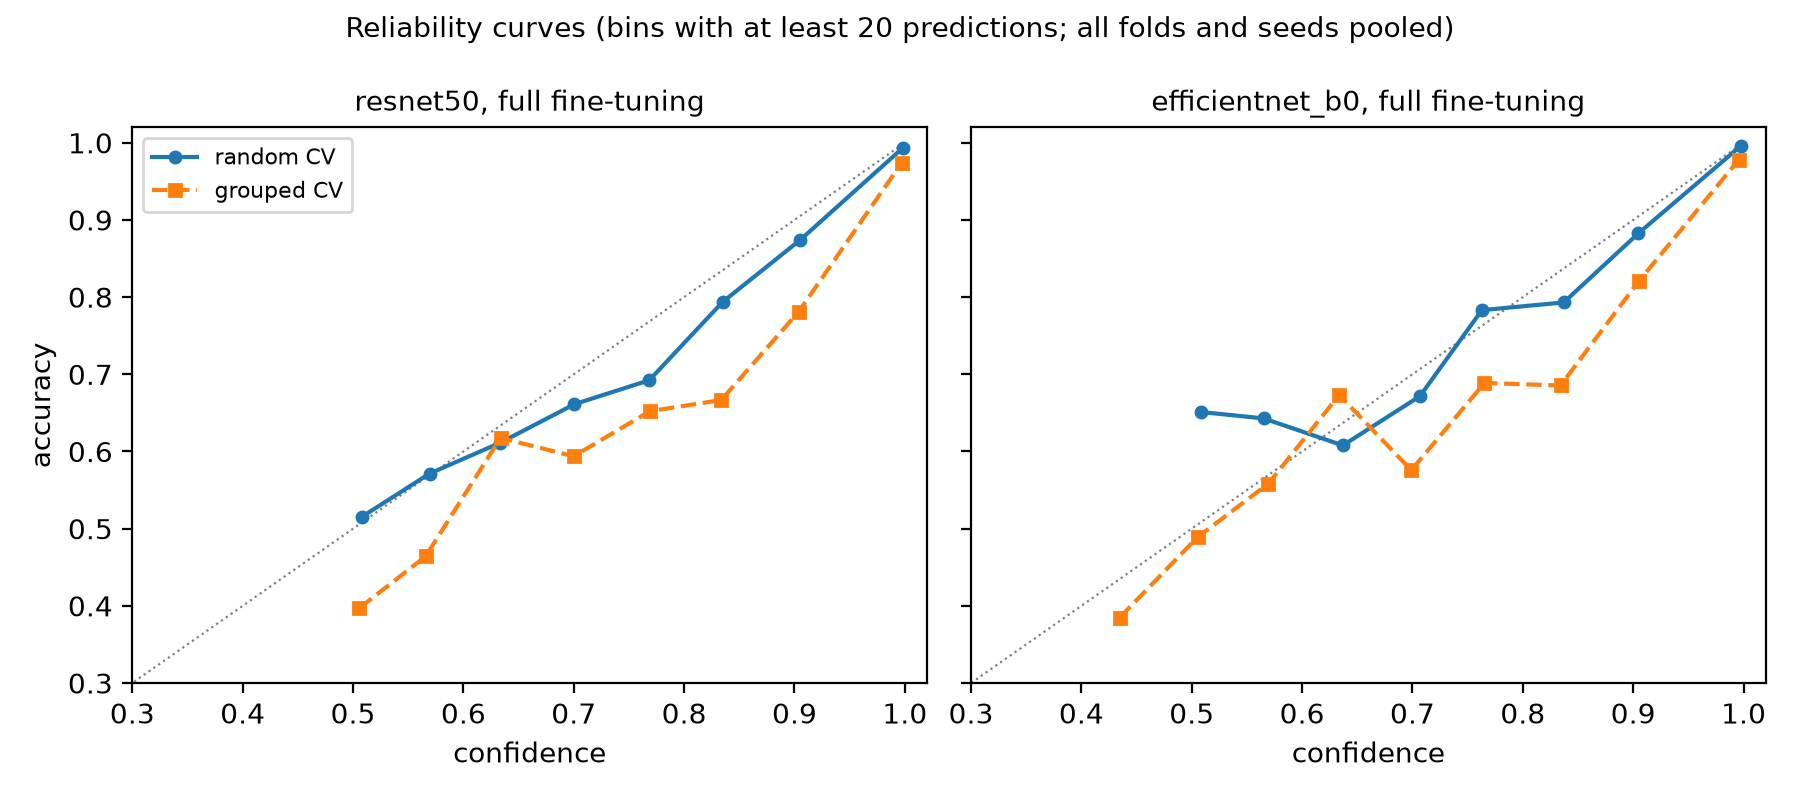

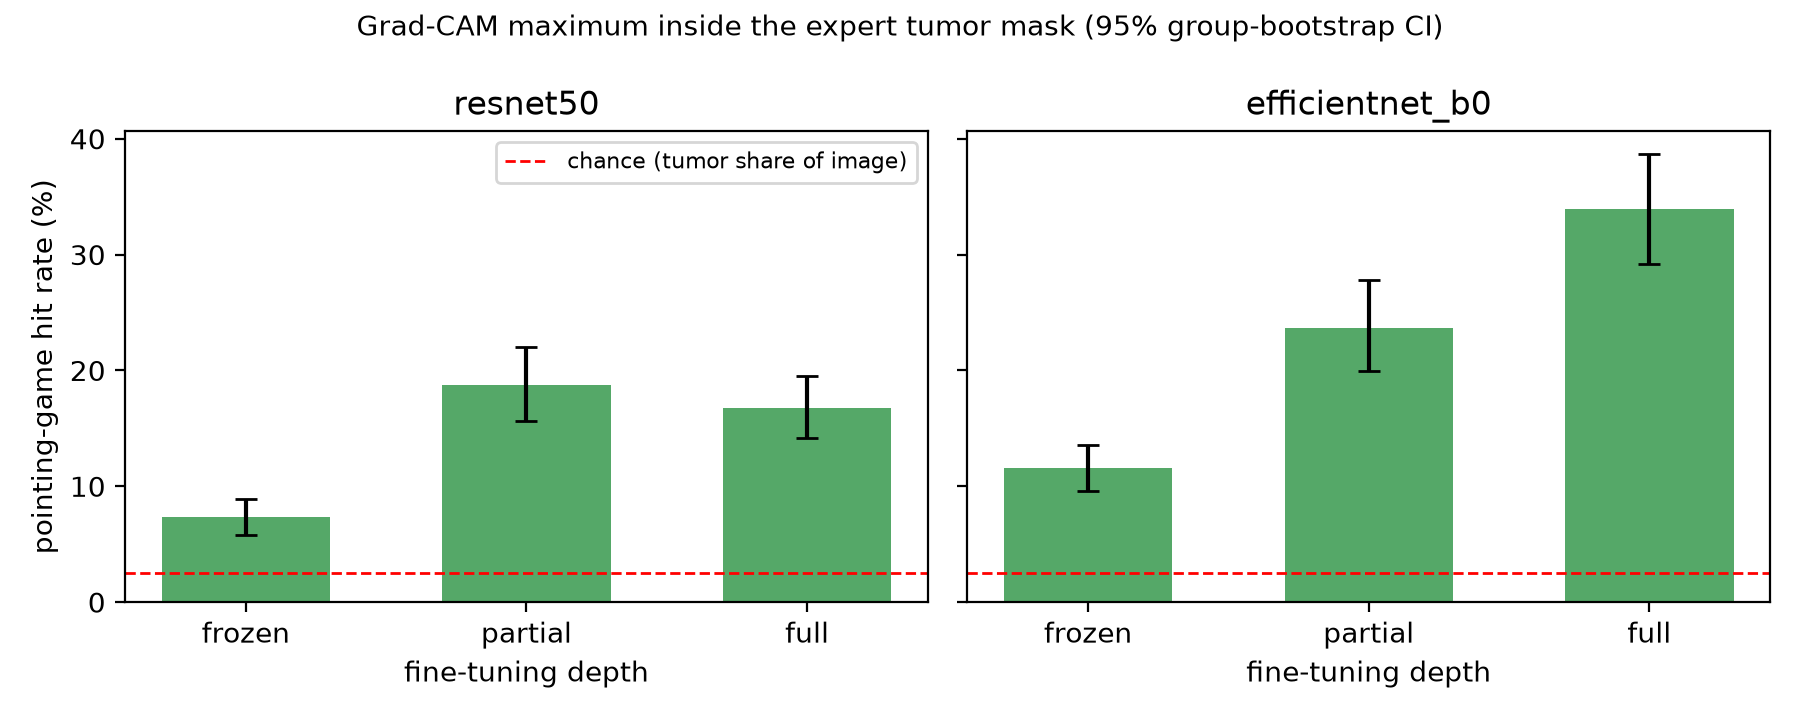

In [49]:
rq2_contrasts, error_ratios, error_ratio_contrasts, recall_gaps = classification(preds)
ece_by_protocol = (per_seed[per_seed.protocol.isin(["random", "grouped"])]
                   .groupby(["arch", "depth", "protocol"]).ece.mean().unstack("protocol"))
ece_by_protocol["grouped_over_random"] = ece_by_protocol["grouped"] / ece_by_protocol["random"]
ece_by_protocol = ece_by_protocol.reset_index()
rq3_correct_vs_incorrect, rq3_per_class = rq3_breakdowns(gradcam_rows, rq3_summary)
reliability(preds)

exploratory_tables = {"expl_rq2_contrasts": rq2_contrasts, "expl_error_ratio": error_ratios,
                      "expl_error_ratio_contrasts": error_ratio_contrasts, "expl_recall_gap_per_class": recall_gaps,
                      "expl_ece_by_protocol": ece_by_protocol, "expl_rq3_correct_vs_incorrect": rq3_correct_vs_incorrect,
                      "expl_rq3_per_class": rq3_per_class}
for name, table in exploratory_tables.items():
    table.to_csv(TABLES / f"{name}.csv", index=False)
    print(f"== {name} ==")
    display(table.round(4))
display(ShowImage(str(FIGS / "fig_reliability_full.png")))
display(ShowImage(str(FIGS / "fig_rq3_pointing.png")))

### An illustrative Grad-CAM panel

The images are **not hand-picked**: two per
tumor class are drawn at random with a fixed seed from grouped-CV test fold 0 of seed 0, among images that have an
expert mask.

**`gradcam_examples(mask_table, masks, seed=0, fold=0, per_class=2)`**

1. Pick the images: for each class, `rng.choice` draws 2 test images with a mask from grouped-CV fold 0 of seed 0
   (random generator with seed 0).
2. For each of the 6 models (2 architectures × 3 depths) of seed 0, fold 0: load the weights and compute Grad-CAM
   for the chosen images.
3. Draw a grid: first column = image with the expert mask outline (cyan contour), then one column per model with
   the heatmap overlaid (`jet` colormap, 45 % opacity), the mask outline, and a white dot at the heatmap maximum.
   Under each panel: the predicted class and whether the dot is inside the mask (hit/miss); wrong predictions in red.
4. Save `results/figures/fig_gradcam_examples.png` and the list of chosen images
   (`results/tables/gradcam_example_images.csv`), and return that list.

The cell below shows the list of chosen images and the figure.


,idx,rel,label
0,1106,Training/glioma/Tr-gl_734.jpg,0
1,5727,Testing/glioma/Te-gl_213.jpg,0
2,1829,Training/meningioma/Tr-me_1295.jpg,1
3,1884,Training/meningioma/Tr-me_174.jpg,1
4,4222,Training/pituitary/Tr-pi_1018.jpg,3
5,4337,Training/pituitary/Tr-pi_1121.jpg,3


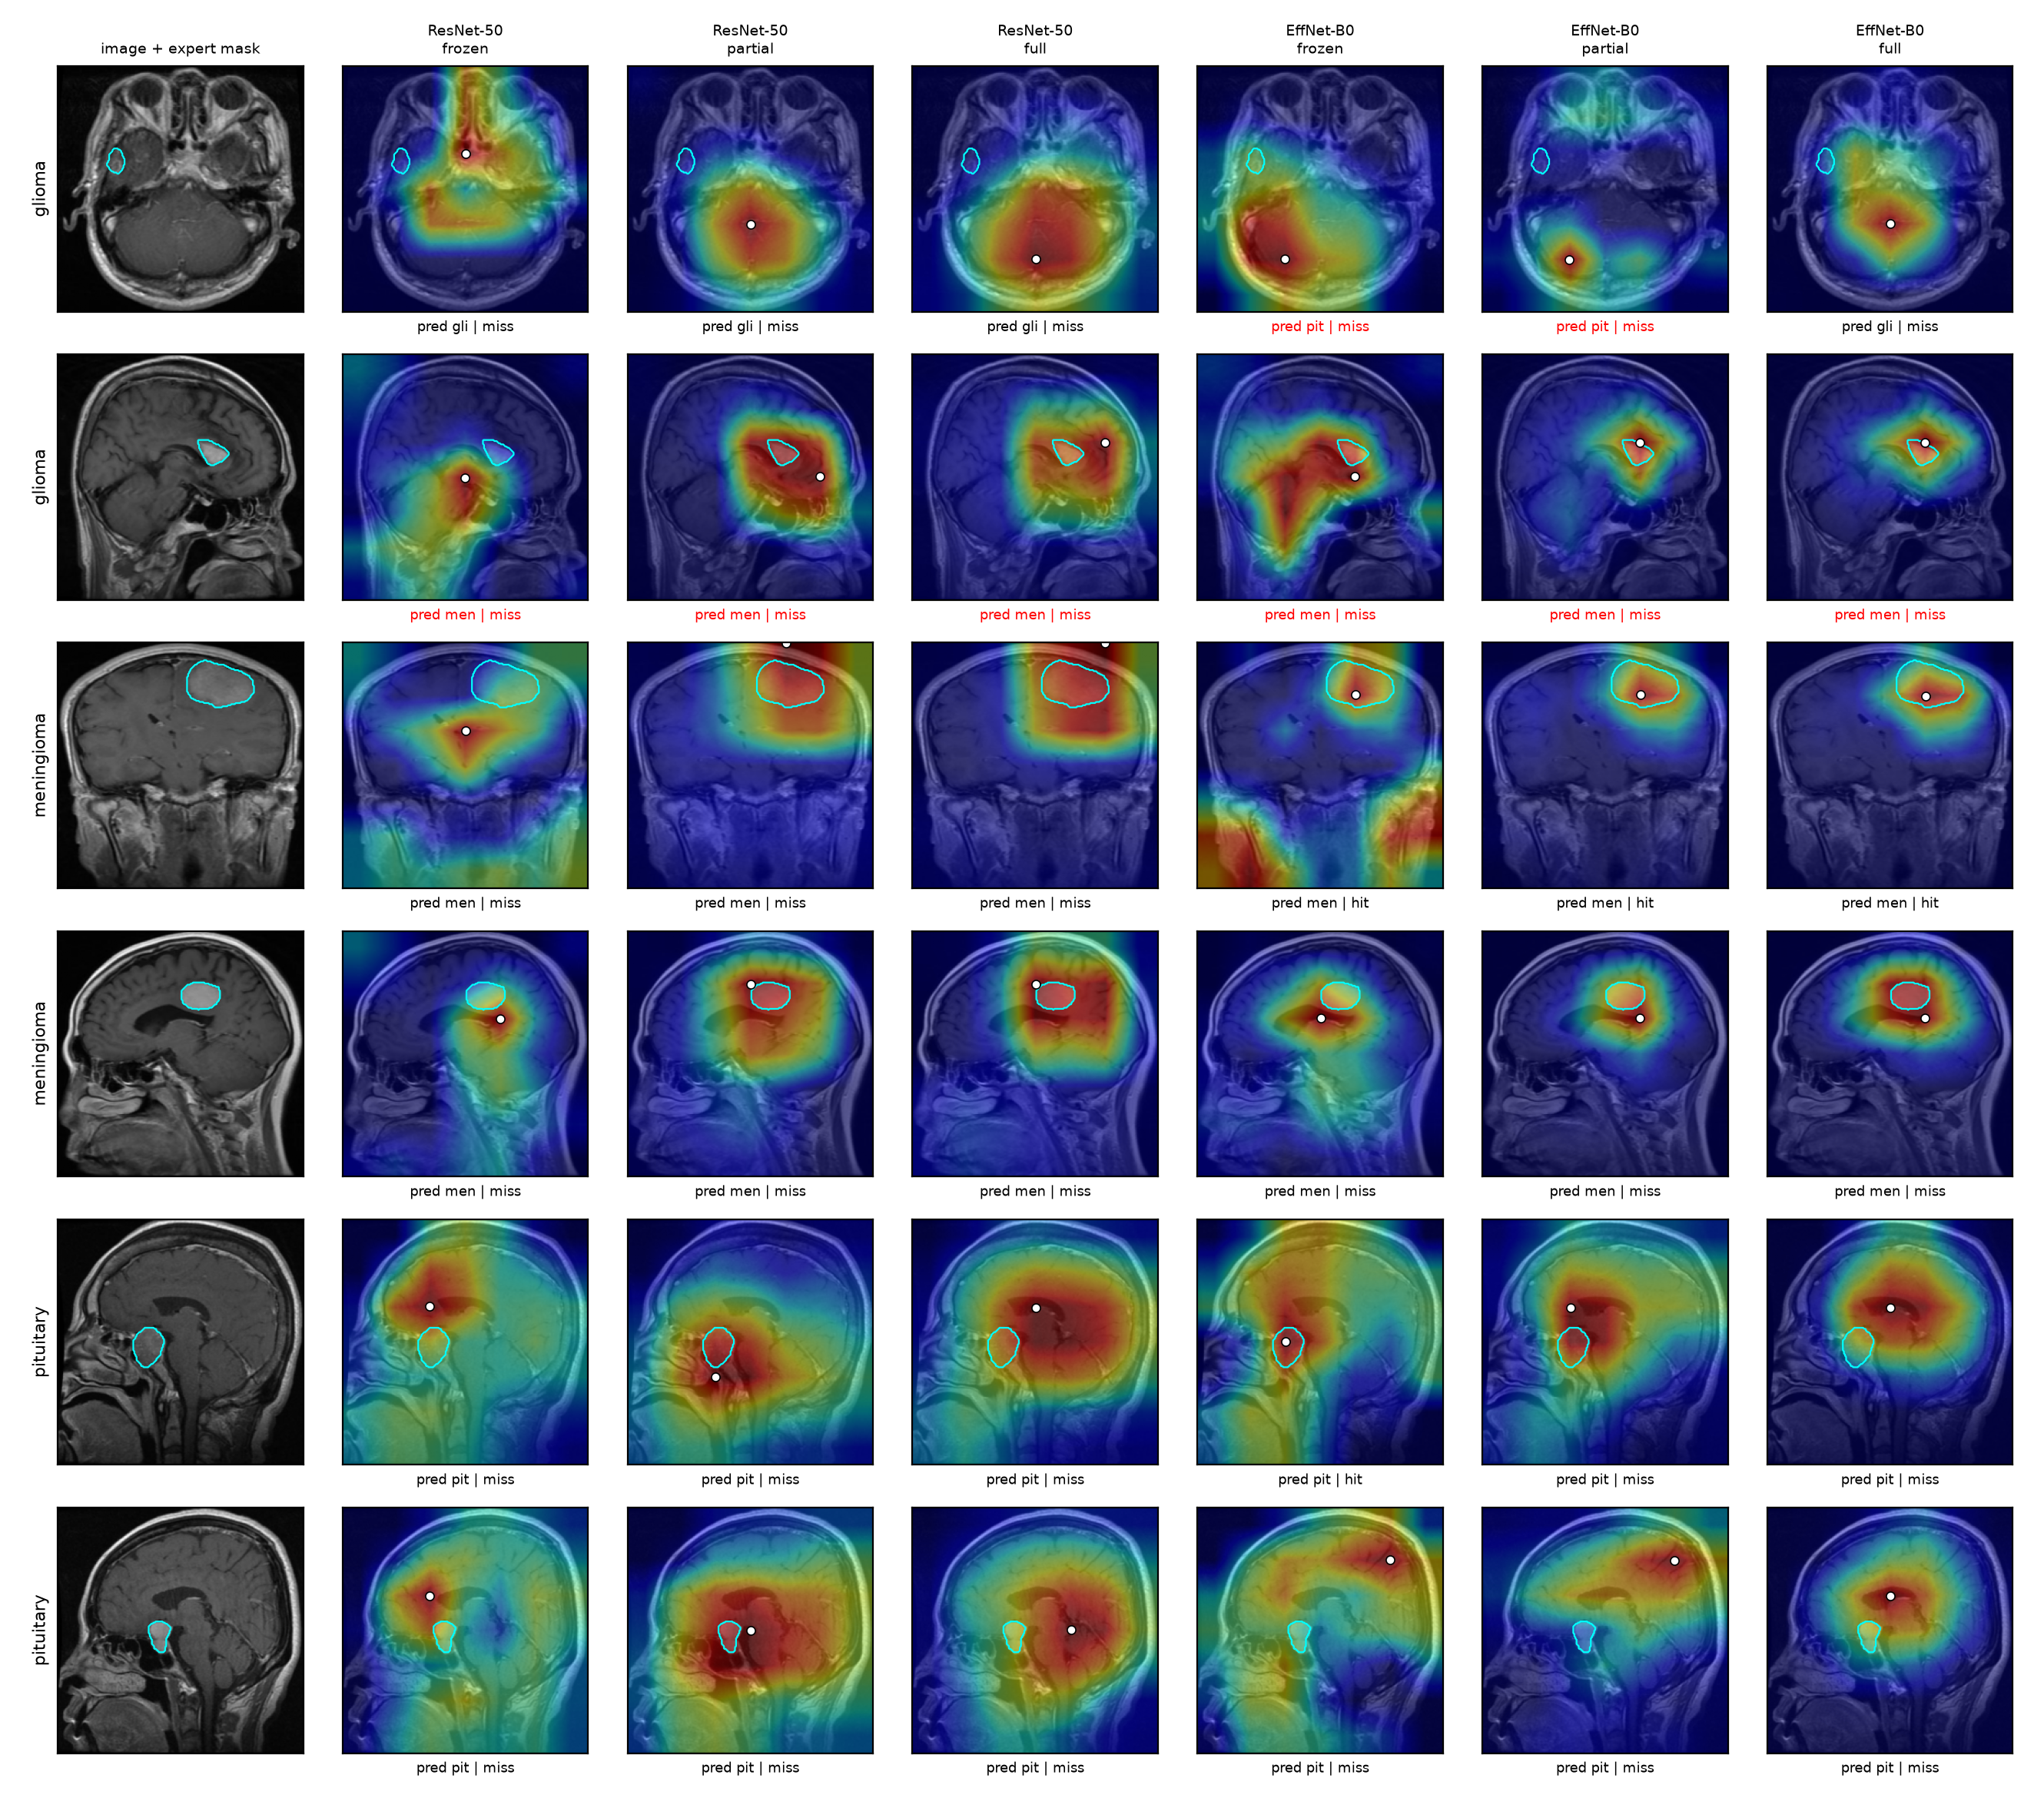

In [50]:
def gradcam_examples(mask_table, masks, seed=0, fold=0, per_class=2):
    matched = mask_table[mask_table.matched]
    mask_pos_of = dict(zip(matched.idx.astype(int), matched.mask_pos.astype(int)))
    labels = index_df["label"].to_numpy()
    _, _, test_idx = get_split(index_df, "grouped", seed, fold)
    rng = np.random.default_rng(0)
    example_idx = []
    for k in range(K):
        candidates = np.array([i for i in test_idx if i in mask_pos_of and labels[i] == k])
        if len(candidates):
            example_idx += sorted(rng.choice(candidates, size=min(per_class, len(candidates)), replace=False).tolist())
    batch = to_input(x_all[torch.as_tensor(example_idx, device=device)])
    configs = [(arch, depth) for arch in ARCHS for depth in DEPTHS]
    cams, model_preds = {}, {}
    for arch, depth in configs:
        model = build_model(arch, depth).to(device)
        model.load_state_dict(torch.load(CHECKPOINTS / f"{run_name('grouped', arch, depth, seed, fold)}.pt",
                                         map_location=device))
        model.eval()
        cam, pred = grad_cam(model, batch)
        cams[(arch, depth)], model_preds[(arch, depth)] = cam.cpu().numpy(), pred.cpu().numpy()

    n_rows, n_cols = len(example_idx), len(configs) + 1
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(1.9 * n_cols, 1.95 * n_rows))
    short = {"glioma": "gli", "meningioma": "men", "notumor": "none", "pituitary": "pit"}
    for row, i in enumerate(example_idx):
        mask = masks[mask_pos_of[i]]
        ax = axes[row, 0]
        ax.imshow(images[i], cmap="gray")
        ax.contour(mask, levels=[0.5], colors="cyan", linewidths=0.8)
        ax.set_ylabel(CLASSES[labels[i]], fontsize=8)
        if row == 0:
            ax.set_title("image + expert mask", fontsize=7)
        for col, (arch, depth) in enumerate(configs, 1):
            ax = axes[row, col]
            cam = cams[(arch, depth)][row]
            ax.imshow(images[i], cmap="gray")
            ax.imshow(cam / max(cam.max(), 1e-9), cmap="jet", alpha=0.45, vmin=0, vmax=1)
            ax.contour(mask, levels=[0.5], colors="cyan", linewidths=0.8)
            peak_y, peak_x = np.unravel_index(int(cam.argmax()), cam.shape)
            ax.plot(peak_x, peak_y, "o", ms=4, mfc="white", mec="black", mew=0.6)
            pred = model_preds[(arch, depth)][row]
            hit = bool(mask[peak_y, peak_x])
            ax.set_xlabel(f"pred {short[CLASSES[pred]]} | {'hit' if hit else 'miss'}", fontsize=6.5,
                          color="black" if pred == labels[i] else "red")
            if row == 0:
                ax.set_title(f"{arch.replace('efficientnet_b0', 'EffNet-B0').replace('resnet50', 'ResNet-50')}\n{depth}", fontsize=7)
    for ax in axes.ravel():
        ax.set_xticks([])
        ax.set_yticks([])
    fig.tight_layout()
    fig.savefig(FIGS / "fig_gradcam_examples.png", dpi=200)
    plt.close(fig)
    example_table = pd.DataFrame({"idx": example_idx, "rel": index_df["rel"].to_numpy()[example_idx],
                                  "label": labels[example_idx]})
    example_table.to_csv(TABLES / "gradcam_example_images.csv", index=False)
    return example_table


display(gradcam_examples(mask_table, masks))
display(ShowImage(str(FIGS / "fig_gradcam_examples.png")))